# Overlap Group-Rep DEG Metrics (Moderated t)

This notebook mirrors `notebooks/overlap_group_rep_signature_similarity.ipynb`, but evaluates matched grouped-replicate sample pairs with DEG-focused metrics.

**t-stats focus (like `overlap_group_rep_retrieval_metrics_t_stats.ipynb`):**
- DEG gene sets are still defined from limma adjusted p-values (`adj.P < 0.05`, optional `|logFC| > 0.2`)
- DEG-restricted Spearman, gene ranking, and direction agreement use moderated t-statistics from `layers["t"]`
- Cluster-BCa CIs and heatmaps are written to `results/overlap_group_rep_deg_metrics_t_stats/`

It starts from the overlap-filtered `.h5ad` files produced by `scripts/build_overlap_filtered_h5ads.py` and reconstructs cross-dataset matches using the same rule:

- same `pubchem_cid`
- same `cell_type`
- same `pert_time_h`
- mutual nearest neighbors in `log10(pert_dose_uM)`
- `|Δ log10 dose| <= 1`
- a `cell_type + pert_time_h` context is included for a dataset pair only if that pair shares at least `10` matched drugs in that context

All DEG metrics are computed on the pairwise shared gene universe for the matched line files, so the comparison stays fair across datasets.

For each matched grouped-replicate sample pair, the notebook evaluates two DEG definitions:

1. `adj.P.Value < 0.05`
2. `adj.P.Value < 0.05` and `|logFC| > 0.2`

The adjusted p-value layer is taken from `adj.P.Value.within_one_contrast` when present, with fallback to `adj.P.Value.across_all_contrasts`.

For each DEG definition, it computes:

1. Symmetric DEG-restricted moderated-t Spearman
   - `0.5 * [ Spearman(t_A, t_B on DE genes from A) + Spearman(t_A, t_B on DE genes from B) ]`
2. Symmetric DE overlap
   - reference-size version using `N = number of DE genes in the reference sample`
   - fixed-`k` versions for `k in {50, 100, 200}`
   - genes ranked by `|t|` within the DEG mask
3. Direction agreement
   - fraction of overlapping DE genes with matching `sign(t)`

Baseline comparison uses the same baseline as in the original notebook: within each dataset, the baseline signature is the mean across all other compounds with the same `cell_type + dose + time` (here on moderated t).

Because the baseline does not have its own limma p-values, baseline DEG metrics are defined from the sample side:

- baseline DEG-restricted t Spearman: Spearman between the sample and its baseline on the sample's DEG genes
- baseline DE overlap: overlap between the sample's ranked DEG genes and the baseline's top-ranked genes by `|t|`
- baseline direction agreement: `sign(t)` agreement between sample and baseline on the sample's DEG genes

For matched cross-dataset pairs, the notebook averages the left-side and right-side baseline scores into a pair baseline and also reports:

- observed cross-dataset score
- baseline pair score
- observed minus baseline pair score

Summaries are computed at three levels:

- matched sample-pair level
- `drug + line + time` level, averaging across matched dose pairs
- dataset-pair and dataset-pair-line level, averaging across `drug + line + time`

Additional sci-Plex vs Tahoe summaries are also reported on an `L1000`-restricted gene set.


In [2]:
from __future__ import annotations

from collections import defaultdict
from dataclasses import dataclass, field
from pathlib import Path
from typing import Optional
import itertools

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import rankdata


sns.set_theme(style="whitegrid")


In [3]:
DATASET_ORDER = [
    "l1000_phase1",
    "l1000_phase2",
    "tahoe",
    "cigs_mce",
    "novartis_batch_2500",
    "vcpi_0001",
    "cigs_tcm",
    "vcpi_0002",
    "gdpx2",
    "sciplex",
    "dilimap_train_val",
    "op3",
]
DISPLAY_LABELS = {
    "l1000_phase1": "L1000 Phase I",
    "l1000_phase2": "L1000 Phase II",
    "tahoe": "Tahoe-100M",
    "cigs_mce": "CIGS-MCE",
    "novartis_batch_2500": "Novartis/DRUG-seq U2OS",
    "vcpi_0001": "VCPI-0001",
    "cigs_tcm": "CIGS-TCM",
    "vcpi_0002": "VCPI-0002",
    "gdpx2": "GDPx2",
    "sciplex": "sci-Plex",
    "dilimap_train_val": "DILImap",
    "op3": "OP3",
}
SOURCE_DATASET_DIRS = {
    "l1000_phase1": Path("/lustre/groups/ml01/workspace/olga.novitskaia/data_updated/l1000_phase1/deg_data/group_rep/full/qc_false/filter_min_cells_0/results"),
    "l1000_phase2": Path("/lustre/groups/ml01/workspace/olga.novitskaia/data_updated/l1000_phase2/deg_data/group_rep/full/qc_false/filter_min_cells_0/results"),
    "tahoe": Path("/lustre/groups/ml01/workspace/olga.novitskaia/data_updated/tahoe/deg_data/group_rep/full/qc_false/filter_min_cells_50/results"),
    "cigs_mce": Path("/lustre/groups/ml01/workspace/olga.novitskaia/data_updated/cigs_mce/deg_data/group_rep/full/qc_false/filter_min_cells_0/results"),
    "novartis_batch_2500": Path("/lustre/groups/ml01/workspace/olga.novitskaia/data_updated/novartis_batch_2500/deg_data/group_rep/full/qc_false/filter_min_cells_0/results"),
    "vcpi_0001": Path("/lustre/groups/ml01/workspace/olga.novitskaia/data_updated/vcpi_0001/deg_data/group_rep/full/qc_false/filter_min_cells_0/results"),
    "cigs_tcm": Path("/lustre/groups/ml01/workspace/olga.novitskaia/data_updated/cigs_tcm/deg_data/group_rep/full/qc_false/filter_min_cells_0/results"),
    "vcpi_0002": Path("/lustre/groups/ml01/workspace/olga.novitskaia/data_updated/vcpi_0002/deg_data/group_rep/full/qc_false/filter_min_cells_0/results"),
    "gdpx2": Path("/lustre/groups/ml01/workspace/olga.novitskaia/data_updated/gdpx2/deg_data/group_rep/full/qc_false/filter_min_cells_0/results"),
    "sciplex": Path("/lustre/groups/ml01/workspace/olga.novitskaia/data_updated/sciplex/deg_data/group_rep/full/qc_false/filter_min_cells_10/results"),
    "dilimap_train_val": Path("/lustre/groups/ml01/workspace/olga.novitskaia/data_updated/dilimap_train_val/deg_data/group_rep/full/qc_false/filter_min_cells_0/results"),
    "op3": Path("/lustre/groups/ml01/workspace/olga.novitskaia/data_updated/op3/deg_data/group_rep/full/qc_false/filter_min_cells_10/results"),
}
MAX_LOG10_DOSE_DIFF = 1.0
MIN_CONTEXT_SHARED_DRUGS = 10
TOP_K = 50
NUMERIC_SIG_FIGS = 12
INVALID_STRING_VALUES = {"", "nan", "none", "<na>"}


def find_repo_root(start=None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "results" / "overlap_filtered_h5ads").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root from the current working directory.")


REPO_ROOT = find_repo_root()
OVERLAP_DIR = REPO_ROOT / "results" / "overlap_filtered_h5ads"
# Shared logFC DEG tables (for optional reuse of matched pairs only).
SHARED_DEG_DIR = REPO_ROOT / "results" / "overlap_group_rep_deg_metrics"
# Organized moderated-t DEG artifacts (metrics, CIs, heatmaps PDF/CSV).
OUTPUT_DIR = REPO_ROOT / "results" / "overlap_group_rep_deg_metrics_t_stats"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FOCUS_EFFECT_LAYER = "t"  # limma moderated t-statistics
# Set True to rebuild metrics from h5ads; False loads precomputed t-stats tables when present.
RECOMPUTE_METRICS = True

print(f"Repository root: {REPO_ROOT}")
print(f"Overlap directory: {OVERLAP_DIR}")
print(f"Shared DEG directory: {SHARED_DEG_DIR}")
print(f"Output directory (t-stats): {OUTPUT_DIR}")
print(f"Focus effect layer: {FOCUS_EFFECT_LAYER}")
print(f"Recompute metrics: {RECOMPUTE_METRICS}")


Repository root: /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis
Overlap directory: /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_filtered_h5ads
Shared DEG directory: /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics
Output directory (t-stats): /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats
Focus effect layer: t
Recompute metrics: True


In [4]:
def pretty_label(dataset_name: str) -> str:
    return DISPLAY_LABELS.get(dataset_name, dataset_name)


def format_numeric(value: float) -> str:
    formatted = f"{value:.{NUMERIC_SIG_FIGS}g}"
    return "0" if formatted == "-0" else formatted


def sanitize_string_values(series: pd.Series) -> pd.Series:
    normalized = series.astype("string").fillna("").astype(str).str.strip()
    normalized.loc[normalized.str.lower().isin(INVALID_STRING_VALUES)] = ""
    return normalized


def format_pubchem_cid(value: float) -> str:
    if float(value).is_integer():
        return str(int(value))
    return format_numeric(float(value))


def normalize_pubchem_cid_values(series: pd.Series) -> pd.Series:
    normalized = sanitize_string_values(series)
    numeric = pd.to_numeric(normalized, errors="coerce")
    finite_mask = np.isfinite(numeric.to_numpy(dtype=float))
    if not finite_mask.any():
        return normalized

    normalized = normalized.copy()
    normalized.loc[finite_mask] = numeric.loc[finite_mask].map(format_pubchem_cid)
    return normalized


def coerce_control_mask(values: pd.Series) -> pd.Series:
    if pd.api.types.is_bool_dtype(values):
        return values.fillna(False).astype(bool)
    normalized = values.astype("string").fillna("").astype(str).str.strip().str.lower()
    return normalized.isin({"true", "1", "yes"})


EMPTY_OVERLAP_FRAME = pd.DataFrame(
    columns=[
        "dataset_name",
        "obs_id",
        "plate",
        "well",
        "pubchem_cid",
        "cell_type",
        "pert_time_h",
        "pert_dose_uM",
        "time_key",
        "dose_key",
        "log10_dose",
    ]
)


def load_overlap_obs(dataset_name: str, overlap_dir: Path = OVERLAP_DIR) -> pd.DataFrame:
    h5ad_path = overlap_dir / f"{dataset_name}_overlap_filtered.h5ad"
    if not h5ad_path.exists():
        raise FileNotFoundError(f"Missing overlap file: {h5ad_path}")

    adata = ad.read_h5ad(h5ad_path, backed="r")
    try:
        obs = adata.obs.copy()
    finally:
        adata.file.close()

    if obs.empty:
        return EMPTY_OVERLAP_FRAME.copy()
    if "is_control" not in obs.columns:
        raise KeyError(f"{h5ad_path} is missing obs['is_control']")

    obs = obs.loc[~coerce_control_mask(obs["is_control"])].copy()
    if obs.empty:
        return EMPTY_OVERLAP_FRAME.copy()

    frame = pd.DataFrame(index=obs.index.copy())
    frame["dataset_name"] = dataset_name
    frame["obs_id"] = frame.index.astype(str)
    frame["plate"] = (
        obs["plate"].astype("string").fillna("").astype(str).str.strip()
        if "plate" in obs.columns
        else ""
    )
    frame["well"] = (
        obs["well"].astype("string").fillna("").astype(str).str.strip()
        if "well" in obs.columns
        else ""
    )
    context_column = "harmonized_context_key" if "harmonized_context_key" in obs.columns else "cell_type"
    frame["pubchem_cid"] = normalize_pubchem_cid_values(obs["pubchem_cid"])
    frame["cell_type"] = sanitize_string_values(obs[context_column])
    frame["pert_time_h"] = pd.to_numeric(obs["pert_time_h"], errors="coerce")
    frame["pert_dose_uM"] = pd.to_numeric(obs["pert_dose_uM"], errors="coerce")

    valid_mask = (
        (frame["pubchem_cid"] != "")
        & (frame["cell_type"] != "")
        & np.isfinite(frame["pert_time_h"].to_numpy(dtype=float))
        & np.isfinite(frame["pert_dose_uM"].to_numpy(dtype=float))
        & (frame["pert_dose_uM"].to_numpy(dtype=float) > 0.0)
    )
    frame = frame.loc[valid_mask].copy().reset_index(drop=True)
    if frame.empty:
        return EMPTY_OVERLAP_FRAME.copy()

    frame["time_key"] = frame["pert_time_h"].map(lambda value: format_numeric(float(value)))
    frame["dose_key"] = frame["pert_dose_uM"].map(lambda value: format_numeric(float(value)))
    frame["log10_dose"] = np.log10(frame["pert_dose_uM"].to_numpy(dtype=np.float64))
    return frame[EMPTY_OVERLAP_FRAME.columns.tolist()]


def ensure_overlap_frame_schema(frame: pd.DataFrame, dataset_name: str) -> pd.DataFrame:
    if frame is None or frame.empty:
        return EMPTY_OVERLAP_FRAME.copy()

    frame = frame.copy()
    if "dataset_name" not in frame.columns:
        frame["dataset_name"] = dataset_name
    else:
        frame["dataset_name"] = frame["dataset_name"].astype("string").fillna(dataset_name).astype(str).str.strip()

    if "obs_id" not in frame.columns:
        frame["obs_id"] = pd.Index(frame.index).astype(str)
    else:
        frame["obs_id"] = frame["obs_id"].astype("string").fillna("").astype(str).str.strip()

    for column_name in ["plate", "well"]:
        if column_name not in frame.columns:
            frame[column_name] = ""
        else:
            frame[column_name] = frame[column_name].astype("string").fillna("").astype(str).str.strip()

    required_columns = ["pubchem_cid", "cell_type", "pert_time_h", "pert_dose_uM"]
    missing_columns = [column_name for column_name in required_columns if column_name not in frame.columns]
    if missing_columns:
        raise KeyError(
            f"Overlap frame for {dataset_name} is missing required columns: {missing_columns}"
        )

    frame["pubchem_cid"] = normalize_pubchem_cid_values(frame["pubchem_cid"])
    frame["cell_type"] = sanitize_string_values(frame["cell_type"])
    frame["pert_time_h"] = pd.to_numeric(frame["pert_time_h"], errors="coerce")
    frame["pert_dose_uM"] = pd.to_numeric(frame["pert_dose_uM"], errors="coerce")

    valid_mask = (
        (frame["pubchem_cid"] != "")
        & (frame["cell_type"] != "")
        & np.isfinite(frame["pert_time_h"].to_numpy(dtype=float))
        & np.isfinite(frame["pert_dose_uM"].to_numpy(dtype=float))
        & (frame["pert_dose_uM"].to_numpy(dtype=float) > 0.0)
    )
    frame = frame.loc[valid_mask].copy().reset_index(drop=True)
    if frame.empty:
        return EMPTY_OVERLAP_FRAME.copy()

    frame["time_key"] = frame["pert_time_h"].map(lambda value: format_numeric(float(value)))
    frame["dose_key"] = frame["pert_dose_uM"].map(lambda value: format_numeric(float(value)))
    frame["log10_dose"] = np.log10(frame["pert_dose_uM"].to_numpy(dtype=np.float64))
    return frame[EMPTY_OVERLAP_FRAME.columns.tolist()]


def build_groups(frame: pd.DataFrame) -> dict[tuple[str, str, str], np.ndarray]:
    if frame.empty:
        return {}
    grouped = frame.groupby(["pubchem_cid", "cell_type", "time_key"], sort=False).groups
    return {
        key: np.asarray(list(row_positions), dtype=np.int64)
        for key, row_positions in grouped.items()
    }


def build_dataset_index(dataset_name: str) -> dict[str, object]:
    frame = ensure_overlap_frame_schema(load_overlap_obs(dataset_name), dataset_name)
    return {
        "frame": frame,
        "groups": build_groups(frame),
    }


def active_dataset_names(dataset_indices: dict[str, dict[str, object]]) -> list[str]:
    return [
        dataset_name
        for dataset_name in DATASET_ORDER
        if dataset_name in dataset_indices and not dataset_indices[dataset_name]["frame"].empty
    ]


def mutual_nearest_logdose_pairs(
    left_log10_doses: np.ndarray,
    right_log10_doses: np.ndarray,
    max_log10_dose_diff: float = MAX_LOG10_DOSE_DIFF,
) -> np.ndarray:
    if left_log10_doses.size == 0 or right_log10_doses.size == 0:
        return np.empty((0, 2), dtype=np.int64)

    diff = np.abs(left_log10_doses[:, None] - right_log10_doses[None, :])
    left_min = diff.min(axis=1, keepdims=True)
    right_min = diff.min(axis=0, keepdims=True)
    is_mnn = (
        (diff <= max_log10_dose_diff + 1e-12)
        & np.isclose(diff, left_min, rtol=0.0, atol=1e-12)
        & np.isclose(diff, right_min, rtol=0.0, atol=1e-12)
    )
    return np.argwhere(is_mnn)


MATCH_PAIR_COLUMNS = [
    "dataset_a",
    "dataset_b",
    "cell_type",
    "pubchem_cid",
    "time_key",
    "left_obs_id",
    "right_obs_id",
    "left_plate",
    "right_plate",
    "left_well",
    "right_well",
    "left_dose_key",
    "right_dose_key",
    "left_log10_dose",
    "right_log10_dose",
    "abs_delta_log10_dose",
    "matched_condition_key",
    "n_context_matching_drugs",
]


def pair_match_frame(
    left_dataset: str,
    right_dataset: str,
    left_index: dict[str, object],
    right_index: dict[str, object],
    *,
    max_log10_dose_diff: float = MAX_LOG10_DOSE_DIFF,
    min_context_shared_drugs: int = MIN_CONTEXT_SHARED_DRUGS,
) -> pd.DataFrame:
    left_frame = ensure_overlap_frame_schema(left_index["frame"], left_dataset)
    right_frame = ensure_overlap_frame_schema(right_index["frame"], right_dataset)
    left_groups = left_index["groups"]
    right_groups = right_index["groups"]

    if set(build_groups(left_frame)) != set(left_groups):
        left_groups = build_groups(left_frame)
    if set(build_groups(right_frame)) != set(right_groups):
        right_groups = build_groups(right_frame)

    if left_frame.empty or right_frame.empty:
        return pd.DataFrame(columns=MATCH_PAIR_COLUMNS)

    shared_keys = sorted(set(left_groups) & set(right_groups))
    if not shared_keys:
        return pd.DataFrame(columns=MATCH_PAIR_COLUMNS)

    left_obs_ids = left_frame["obs_id"].to_numpy(dtype=object)
    right_obs_ids = right_frame["obs_id"].to_numpy(dtype=object)
    left_plates = left_frame["plate"].to_numpy(dtype=object)
    right_plates = right_frame["plate"].to_numpy(dtype=object)
    left_wells = left_frame["well"].to_numpy(dtype=object)
    right_wells = right_frame["well"].to_numpy(dtype=object)
    left_log10_dose = left_frame["log10_dose"].to_numpy(dtype=np.float64)
    right_log10_dose = right_frame["log10_dose"].to_numpy(dtype=np.float64)
    left_dose_keys = left_frame["dose_key"].to_numpy(dtype=object)
    right_dose_keys = right_frame["dose_key"].to_numpy(dtype=object)

    context_matching_drugs: dict[tuple[str, str], set[str]] = defaultdict(set)
    rows: list[dict[str, object]] = []

    for pubchem_cid, cell_type, time_key in shared_keys:
        left_rows = left_groups[(pubchem_cid, cell_type, time_key)]
        right_rows = right_groups[(pubchem_cid, cell_type, time_key)]
        pairs = mutual_nearest_logdose_pairs(
            left_log10_doses=left_log10_dose[left_rows],
            right_log10_doses=right_log10_dose[right_rows],
            max_log10_dose_diff=max_log10_dose_diff,
        )
        if pairs.size == 0:
            continue

        for left_pos, right_pos in pairs:
            left_row = int(left_rows[left_pos])
            right_row = int(right_rows[right_pos])
            left_dose_key = str(left_dose_keys[left_row])
            right_dose_key = str(right_dose_keys[right_row])
            context_matching_drugs[(str(cell_type), str(time_key))].add(str(pubchem_cid))
            rows.append(
                {
                    "dataset_a": left_dataset,
                    "dataset_b": right_dataset,
                    "cell_type": str(cell_type),
                    "pubchem_cid": str(pubchem_cid),
                    "time_key": str(time_key),
                    "left_obs_id": str(left_obs_ids[left_row]),
                    "right_obs_id": str(right_obs_ids[right_row]),
                    "left_plate": str(left_plates[left_row]),
                    "right_plate": str(right_plates[right_row]),
                    "left_well": str(left_wells[left_row]),
                    "right_well": str(right_wells[right_row]),
                    "left_dose_key": left_dose_key,
                    "right_dose_key": right_dose_key,
                    "left_log10_dose": float(left_log10_dose[left_row]),
                    "right_log10_dose": float(right_log10_dose[right_row]),
                    "abs_delta_log10_dose": float(abs(left_log10_dose[left_row] - right_log10_dose[right_row])),
                    "matched_condition_key": "|".join(
                        [
                            str(pubchem_cid),
                            str(cell_type),
                            str(time_key),
                            left_dose_key,
                            right_dose_key,
                        ]
                    ),
                }
            )

    if not rows:
        return pd.DataFrame(columns=MATCH_PAIR_COLUMNS)

    frame = pd.DataFrame(rows)
    qualifying_context_drug_counts = {
        context_key: len(compounds)
        for context_key, compounds in context_matching_drugs.items()
        if len(compounds) >= int(min_context_shared_drugs)
    }
    if not qualifying_context_drug_counts:
        return pd.DataFrame(columns=MATCH_PAIR_COLUMNS)

    frame["_context_key"] = list(zip(frame["cell_type"], frame["time_key"]))
    frame["n_context_matching_drugs"] = frame["_context_key"].map(qualifying_context_drug_counts)
    frame = frame.loc[frame["n_context_matching_drugs"].notna()].copy()
    frame["n_context_matching_drugs"] = frame["n_context_matching_drugs"].astype(int)
    frame = frame.drop(columns="_context_key")
    return frame[MATCH_PAIR_COLUMNS].reset_index(drop=True)



In [5]:
@dataclass
class LineSource:
    dataset_name: str
    cell_type: str
    path: Path
    adata: ad.AnnData = field(init=False, repr=False)
    obs: pd.DataFrame = field(init=False, repr=False)
    unique_gene_keys: np.ndarray = field(init=False, repr=False)
    unique_gene_positions: np.ndarray = field(init=False, repr=False)
    gene_to_pos: dict[str, int] = field(init=False, repr=False)
    lookup_row_pos: dict[str, int] = field(init=False, repr=False)
    _vector_cache: dict[tuple[str, int], np.ndarray] = field(default_factory=dict, init=False, repr=False)
    _baseline_cache: dict[tuple[str, int], object] = field(default_factory=dict, init=False, repr=False)
    _baseline_peer_counts: dict[int, int] = field(default_factory=dict, init=False, repr=False)

    def __post_init__(self) -> None:
        self.adata = ad.read_h5ad(self.path, backed="r")
        obs = self.adata.obs.copy()
        row_positions = np.arange(self.adata.n_obs, dtype=np.int64)

        if "is_control" not in obs.columns:
            raise KeyError(f"{self.path} is missing obs['is_control']")

        obs["source_index"] = obs.index.astype(str)
        control_mask = coerce_control_mask(obs["is_control"]).to_numpy(dtype=bool)
        obs = obs.loc[~control_mask].copy()
        row_positions = row_positions[~control_mask]

        obs["source_row_pos"] = row_positions
        for column_name in [
            "id",
            "plate",
            "well",
            "cell_type",
            "perturbagen",
            "perturbagen_name",
            "perturbation_label",
            "pubchem_cid",
        ]:
            if column_name in obs.columns:
                obs[column_name] = obs[column_name].astype("string").fillna("").astype(str).str.strip()

        if "pubchem_cid" in obs.columns:
            obs["pubchem_cid"] = normalize_pubchem_cid_values(obs["pubchem_cid"])

        obs["pert_time_h"] = pd.to_numeric(obs["pert_time_h"], errors="coerce")
        obs["pert_dose_uM"] = pd.to_numeric(obs["pert_dose_uM"], errors="coerce")
        obs["time_key"] = obs["pert_time_h"].map(
            lambda value: format_numeric(float(value)) if pd.notna(value) else ""
        )
        obs["dose_key"] = obs["pert_dose_uM"].map(
            lambda value: format_numeric(float(value)) if pd.notna(value) and float(value) > 0 else ""
        )

        valid_mask = (
            (obs["pubchem_cid"] != "")
            & np.isfinite(obs["pert_time_h"].to_numpy(dtype=float))
            & np.isfinite(obs["pert_dose_uM"].to_numpy(dtype=float))
            & (obs["pert_dose_uM"].to_numpy(dtype=float) > 0.0)
        )
        obs = obs.loc[valid_mask].copy()
        obs = obs.set_index("source_row_pos", drop=False)
        self.obs = obs
        self.lookup_row_pos = self._build_lookup_row_pos()

        var = self.adata.var.copy()
        if "symbol" in var.columns:
            gene_key_series = pd.Series(
                var["symbol"].astype("string").fillna("").astype(str).str.strip().to_numpy(),
                index=np.arange(self.adata.n_vars, dtype=np.int64),
            )
        else:
            gene_key_series = pd.Series(
                pd.Index(self.adata.var_names.astype(str)).astype(str).str.strip().to_numpy(),
                index=np.arange(self.adata.n_vars, dtype=np.int64),
            )
        keep_mask = (gene_key_series != "") & ~gene_key_series.duplicated(keep="first")
        self.unique_gene_positions = gene_key_series.index[keep_mask].to_numpy(dtype=np.int64)
        self.unique_gene_keys = gene_key_series.loc[keep_mask].to_numpy(dtype=object)
        self.gene_to_pos = {
            str(gene_key): int(pos)
            for pos, gene_key in enumerate(self.unique_gene_keys.tolist())
        }

    def _build_lookup_row_pos(self) -> dict[str, int]:
        lookup_row_pos: dict[str, int] = {}

        def add_lookup_key(key: str, row_pos: int) -> None:
            if not key or key.lower() == "nan":
                return
            lookup_row_pos.setdefault(key, row_pos)

        for row_pos, row in self.obs.iterrows():
            row_pos = int(row_pos)
            for column_name in ["source_index", "id"]:
                if column_name in row.index:
                    add_lookup_key(str(row[column_name]).strip(), row_pos)

            cell_type = str(row.get("cell_type", "")).strip()
            pubchem_cid = str(row.get("pubchem_cid", "")).strip()
            dose_key = str(row.get("dose_key", "")).strip()
            time_key = str(row.get("time_key", "")).strip()

            if pubchem_cid and dose_key and time_key and cell_type:
                add_lookup_key(
                    f"{pubchem_cid}|{dose_key}|{time_key}|{cell_type}",
                    row_pos,
                )
        return lookup_row_pos

    def resolve_row_pos(
        self,
        obs_id: str,
        *,
        pubchem_cid=None,
        dose_key=None,
        time_key=None,
        plate=None,
        well=None,
    ) -> int:
        obs_id = str(obs_id)
        candidate_keys = [obs_id]

        pubchem_cid = "" if pubchem_cid is None else str(pubchem_cid).strip()
        dose_key = "" if dose_key is None else str(dose_key).strip()
        time_key = "" if time_key is None else str(time_key).strip()

        if pubchem_cid and dose_key and time_key:
            candidate_keys.append(f"{pubchem_cid}|{dose_key}|{time_key}|{self.cell_type}")

        for candidate_key in candidate_keys:
            if candidate_key in self.lookup_row_pos:
                return int(self.lookup_row_pos[candidate_key])

        raise KeyError(
            f"Could not resolve obs_id={obs_id!r} in {self.path}. "
            f"Tried {candidate_keys!r}. Available lookup keys: {len(self.lookup_row_pos):,}"
        )

    def get_vector(
        self,
        obs_id: str,
        layer_name: str,
        *,
        pubchem_cid=None,
        dose_key=None,
        time_key=None,
        plate=None,
        well=None,
    ) -> np.ndarray:
        row_pos = self.resolve_row_pos(
            obs_id,
            pubchem_cid=pubchem_cid,
            dose_key=dose_key,
            time_key=time_key,
            plate=plate,
            well=well,
        )
        cache_key = (layer_name, row_pos)
        if cache_key not in self._vector_cache:
            vector = np.asarray(self.adata.layers[layer_name][row_pos], dtype=np.float32).reshape(-1)
            self._vector_cache[cache_key] = vector[self.unique_gene_positions]
        return self._vector_cache[cache_key]

    def get_baseline_vector(
        self,
        obs_id: str,
        layer_name: str,
        *,
        pubchem_cid=None,
        dose_key=None,
        time_key=None,
        plate=None,
        well=None,
    ):
        row_pos = self.resolve_row_pos(
            obs_id,
            pubchem_cid=pubchem_cid,
            dose_key=dose_key,
            time_key=time_key,
            plate=plate,
            well=well,
        )
        cache_key = (layer_name, row_pos)
        if cache_key not in self._baseline_cache:
            row = self.obs.loc[row_pos]
            peer_obs = self.obs.loc[
                (self.obs["dose_key"] == row["dose_key"])
                & (self.obs["time_key"] == row["time_key"])
                & (self.obs["pubchem_cid"] != row["pubchem_cid"])
            ]
            peer_rows = peer_obs["source_row_pos"].to_numpy(dtype=np.int64)
            self._baseline_peer_counts[row_pos] = int(len(peer_rows))
            if len(peer_rows) == 0:
                self._baseline_cache[cache_key] = None
            else:
                matrix = np.asarray(self.adata.layers[layer_name][peer_rows], dtype=np.float32)
                if matrix.ndim == 1:
                    matrix = matrix[np.newaxis, :]
                baseline = matrix[:, self.unique_gene_positions].mean(axis=0, dtype=np.float64)
                self._baseline_cache[cache_key] = np.asarray(baseline, dtype=np.float32)
        return self._baseline_cache[cache_key]

    def baseline_peer_count(
        self,
        obs_id: str,
        *,
        pubchem_cid=None,
        dose_key=None,
        time_key=None,
        plate=None,
        well=None,
    ) -> int:
        row_pos = self.resolve_row_pos(
            obs_id,
            pubchem_cid=pubchem_cid,
            dose_key=dose_key,
            time_key=time_key,
            plate=plate,
            well=well,
        )
        if row_pos not in self._baseline_peer_counts:
            _ = self.get_baseline_vector(
                obs_id,
                "logFC",
                pubchem_cid=pubchem_cid,
                dose_key=dose_key,
                time_key=time_key,
                plate=plate,
                well=well,
            )
        return int(self._baseline_peer_counts.get(row_pos, 0))

    def close(self) -> None:
        self.adata.file.close()


def resolve_line_path(dataset_name: str, cell_type: str) -> Path:
    dataset_dir = SOURCE_DATASET_DIRS[dataset_name]
    candidates = [
        dataset_dir / f"{cell_type}_de.h5ad",
        dataset_dir / f"{cell_type}.h5ad",
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f"Could not find a line file for dataset={dataset_name}, cell_type={cell_type} in {dataset_dir}"
    )


LINE_SOURCE_CACHE: dict[tuple[str, str], LineSource] = {}
COMMON_GENE_CACHE: dict[tuple[str, str, str], tuple[np.ndarray, np.ndarray, np.ndarray]] = {}


def get_line_source(dataset_name: str, cell_type: str) -> LineSource:
    cache_key = (dataset_name, cell_type)
    if cache_key not in LINE_SOURCE_CACHE:
        LINE_SOURCE_CACHE[cache_key] = LineSource(
            dataset_name=dataset_name,
            cell_type=cell_type,
            path=resolve_line_path(dataset_name, cell_type),
        )
    return LINE_SOURCE_CACHE[cache_key]


def shared_gene_positions(
    left_source: LineSource,
    right_source: LineSource,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    cache_key = (left_source.dataset_name, right_source.dataset_name, left_source.cell_type)
    if cache_key not in COMMON_GENE_CACHE:
        shared_genes = [
            gene_key
            for gene_key in left_source.unique_gene_keys.tolist()
            if str(gene_key) in right_source.gene_to_pos
        ]
        left_positions = np.fromiter(
            (left_source.gene_to_pos[str(gene_key)] for gene_key in shared_genes),
            dtype=np.int64,
            count=len(shared_genes),
        )
        right_positions = np.fromiter(
            (right_source.gene_to_pos[str(gene_key)] for gene_key in shared_genes),
            dtype=np.int64,
            count=len(shared_genes),
        )
        COMMON_GENE_CACHE[cache_key] = (
            np.asarray(shared_genes, dtype=object),
            left_positions,
            right_positions,
        )
    return COMMON_GENE_CACHE[cache_key]

LINE_GLOBAL_SHARED_GENE_KEYS: dict[str, np.ndarray] = {}
GLOBAL_GENE_POSITION_CACHE: dict[tuple[str, str], np.ndarray] = {}


def set_global_shared_gene_keys(
    retained_lines: dict[str, list[str]],
    dataset_names: list[str],
) -> dict[str, np.ndarray]:
    global LINE_GLOBAL_SHARED_GENE_KEYS, GLOBAL_GENE_POSITION_CACHE

    cell_types = sorted(
        {
            cell_type
            for dataset_name in dataset_names
            for cell_type in retained_lines.get(dataset_name, [])
        }
    )
    line_gene_map: dict[str, np.ndarray] = {}
    for cell_type in cell_types:
        gene_sets: list[set[str]] = []
        for dataset_name in dataset_names:
            if cell_type not in retained_lines.get(dataset_name, []):
                continue
            source = get_line_source(dataset_name, cell_type)
            gene_sets.append({str(gene_key) for gene_key in source.unique_gene_keys.tolist()})
        if not gene_sets:
            line_gene_map[cell_type] = np.empty(0, dtype=object)
        else:
            line_gene_map[cell_type] = np.asarray(sorted(set.intersection(*gene_sets)), dtype=object)

    LINE_GLOBAL_SHARED_GENE_KEYS = line_gene_map
    GLOBAL_GENE_POSITION_CACHE = {}
    return LINE_GLOBAL_SHARED_GENE_KEYS


def global_gene_positions(source: LineSource) -> tuple[np.ndarray, np.ndarray]:
    cache_key = (source.dataset_name, source.cell_type)
    line_gene_keys = LINE_GLOBAL_SHARED_GENE_KEYS.get(source.cell_type, np.empty(0, dtype=object))
    if line_gene_keys.size == 0:
        return line_gene_keys, np.empty(0, dtype=np.int64)
    if cache_key not in GLOBAL_GENE_POSITION_CACHE:
        missing_gene_keys = [
            str(gene_key)
            for gene_key in line_gene_keys.tolist()
            if str(gene_key) not in source.gene_to_pos
        ]
        if missing_gene_keys:
            raise KeyError(
                f"Line-specific shared-gene set is inconsistent for {(source.dataset_name, source.cell_type)}; "
                f"missing {len(missing_gene_keys)} genes."
            )
        GLOBAL_GENE_POSITION_CACHE[cache_key] = np.fromiter(
            (source.gene_to_pos[str(gene_key)] for gene_key in line_gene_keys.tolist()),
            dtype=np.int64,
            count=int(line_gene_keys.size),
        )
    return line_gene_keys, GLOBAL_GENE_POSITION_CACHE[cache_key]



def filter_finite_pair(left_values: np.ndarray, right_values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    mask = np.isfinite(left_values) & np.isfinite(right_values)
    return left_values[mask], right_values[mask]


def signed_spearman(left_values: np.ndarray, right_values: np.ndarray) -> float:
    left_values, right_values = filter_finite_pair(
        np.asarray(left_values, dtype=np.float64),
        np.asarray(right_values, dtype=np.float64),
    )
    if left_values.size < 2:
        return float("nan")

    left_ranks = rankdata(left_values, method="average")
    right_ranks = rankdata(right_values, method="average")
    if np.allclose(left_ranks, left_ranks[0]) or np.allclose(right_ranks, right_ranks[0]):
        return float("nan")
    return float(np.corrcoef(left_ranks, right_ranks)[0, 1])


def signed_overlap_at_k(left_values: np.ndarray, right_values: np.ndarray, *, k: int = TOP_K) -> float:
    left_values, right_values = filter_finite_pair(
        np.asarray(left_values, dtype=np.float64),
        np.asarray(right_values, dtype=np.float64),
    )
    n_genes = int(left_values.size)
    k_eff = min(int(k), n_genes // 2)
    if k_eff < 1:
        return float("nan")

    top_left = np.argpartition(left_values, -k_eff)[-k_eff:]
    top_right = np.argpartition(right_values, -k_eff)[-k_eff:]
    bottom_left = np.argpartition(left_values, k_eff - 1)[:k_eff]
    bottom_right = np.argpartition(right_values, k_eff - 1)[:k_eff]

    top_overlap = np.intersect1d(top_left, top_right, assume_unique=False).size / k_eff
    bottom_overlap = np.intersect1d(bottom_left, bottom_right, assume_unique=False).size / k_eff
    return float(0.5 * (top_overlap + bottom_overlap))


def score_signature_pair(
    left_logfc: np.ndarray,
    right_logfc: np.ndarray,
    left_t: np.ndarray,
    right_t: np.ndarray,
) -> dict[str, float]:
    return {
        "spearman_logfc": signed_spearman(left_logfc, right_logfc),
        "spearman_t": signed_spearman(left_t, right_t),
        f"signed_overlap_t_top{TOP_K}": signed_overlap_at_k(left_t, right_t, k=TOP_K),
    }


def mean_available(values: list[float]) -> float:
    finite_values = [value for value in values if pd.notna(value)]
    if not finite_values:
        return float("nan")
    return float(np.mean(finite_values))

def empty_score_dict() -> dict[str, float]:
    return {
        "spearman_logfc": float("nan"),
        "spearman_t": float("nan"),
        f"signed_overlap_t_top{TOP_K}": float("nan"),
    }



def compute_metric_record(match_row: pd.Series) -> dict[str, object]:
    left_source = get_line_source(str(match_row["dataset_a"]), str(match_row["cell_type"]))
    right_source = get_line_source(str(match_row["dataset_b"]), str(match_row["cell_type"]))
    shared_genes, left_gene_pos, right_gene_pos = shared_gene_positions(left_source, right_source)
    if shared_genes.size < 2:
        raise ValueError(
            f"Fewer than two shared genes for {match_row['dataset_a']} vs {match_row['dataset_b']} / {match_row['cell_type']}"
        )

    global_shared_genes, left_global_gene_pos = global_gene_positions(left_source)
    _, right_global_gene_pos = global_gene_positions(right_source)

    left_obs_id = str(match_row["left_obs_id"])
    right_obs_id = str(match_row["right_obs_id"])
    pubchem_cid = str(match_row["pubchem_cid"])
    time_key = str(match_row["time_key"])

    left_lookup = {
        "pubchem_cid": pubchem_cid,
        "dose_key": str(match_row["left_dose_key"]),
        "time_key": time_key,
    }
    right_lookup = {
        "pubchem_cid": pubchem_cid,
        "dose_key": str(match_row["right_dose_key"]),
        "time_key": time_key,
    }

    left_logfc_full = left_source.get_vector(left_obs_id, "logFC", **left_lookup)
    right_logfc_full = right_source.get_vector(right_obs_id, "logFC", **right_lookup)
    left_t_full = left_source.get_vector(left_obs_id, "t", **left_lookup)
    right_t_full = right_source.get_vector(right_obs_id, "t", **right_lookup)

    observed_scores = score_signature_pair(
        left_logfc=left_logfc_full[left_gene_pos],
        right_logfc=right_logfc_full[right_gene_pos],
        left_t=left_t_full[left_gene_pos],
        right_t=right_t_full[right_gene_pos],
    )

    observed_scores_global = empty_score_dict()
    if global_shared_genes.size >= 2:
        observed_scores_global = score_signature_pair(
            left_logfc=left_logfc_full[left_global_gene_pos],
            right_logfc=right_logfc_full[right_global_gene_pos],
            left_t=left_t_full[left_global_gene_pos],
            right_t=right_t_full[right_global_gene_pos],
        )

    left_mean_abs_t = mean_available(np.abs(left_t_full[left_gene_pos]).tolist())
    right_mean_abs_t = mean_available(np.abs(right_t_full[right_gene_pos]).tolist())
    pair_mean_abs_t = mean_available([left_mean_abs_t, right_mean_abs_t])

    left_mean_abs_t_global = float("nan")
    right_mean_abs_t_global = float("nan")
    pair_mean_abs_t_global = float("nan")
    if global_shared_genes.size >= 2:
        left_mean_abs_t_global = mean_available(np.abs(left_t_full[left_global_gene_pos]).tolist())
        right_mean_abs_t_global = mean_available(np.abs(right_t_full[right_global_gene_pos]).tolist())
        pair_mean_abs_t_global = mean_available([left_mean_abs_t_global, right_mean_abs_t_global])

    left_baseline_logfc_full = left_source.get_baseline_vector(left_obs_id, "logFC", **left_lookup)
    left_baseline_t_full = left_source.get_baseline_vector(left_obs_id, "t", **left_lookup)
    right_baseline_logfc_full = right_source.get_baseline_vector(right_obs_id, "logFC", **right_lookup)
    right_baseline_t_full = right_source.get_baseline_vector(right_obs_id, "t", **right_lookup)

    left_baseline_scores = empty_score_dict()
    left_baseline_scores_global = empty_score_dict()
    if left_baseline_logfc_full is not None and left_baseline_t_full is not None:
        left_baseline_scores = score_signature_pair(
            left_logfc=left_logfc_full[left_gene_pos],
            right_logfc=left_baseline_logfc_full[left_gene_pos],
            left_t=left_t_full[left_gene_pos],
            right_t=left_baseline_t_full[left_gene_pos],
        )
        if global_shared_genes.size >= 2:
            left_baseline_scores_global = score_signature_pair(
                left_logfc=left_logfc_full[left_global_gene_pos],
                right_logfc=left_baseline_logfc_full[left_global_gene_pos],
                left_t=left_t_full[left_global_gene_pos],
                right_t=left_baseline_t_full[left_global_gene_pos],
            )

    right_baseline_scores = empty_score_dict()
    right_baseline_scores_global = empty_score_dict()
    if right_baseline_logfc_full is not None and right_baseline_t_full is not None:
        right_baseline_scores = score_signature_pair(
            left_logfc=right_logfc_full[right_gene_pos],
            right_logfc=right_baseline_logfc_full[right_gene_pos],
            left_t=right_t_full[right_gene_pos],
            right_t=right_baseline_t_full[right_gene_pos],
        )
        if global_shared_genes.size >= 2:
            right_baseline_scores_global = score_signature_pair(
                left_logfc=right_logfc_full[right_global_gene_pos],
                right_logfc=right_baseline_logfc_full[right_global_gene_pos],
                left_t=right_t_full[right_global_gene_pos],
                right_t=right_baseline_t_full[right_global_gene_pos],
            )

    overlap_column = f"signed_overlap_t_top{TOP_K}"
    return {
        **match_row.to_dict(),
        "n_common_genes": int(shared_genes.size),
        "n_global_common_genes": int(global_shared_genes.size),
        "left_mean_abs_t": left_mean_abs_t,
        "right_mean_abs_t": right_mean_abs_t,
        "pair_mean_abs_t": pair_mean_abs_t,
        "left_mean_abs_t_global": left_mean_abs_t_global,
        "right_mean_abs_t_global": right_mean_abs_t_global,
        "pair_mean_abs_t_global": pair_mean_abs_t_global,
        "observed_spearman_logfc": observed_scores["spearman_logfc"],
        "observed_spearman_logfc_global": observed_scores_global["spearman_logfc"],
        "observed_spearman_t": observed_scores["spearman_t"],
        "observed_spearman_t_global": observed_scores_global["spearman_t"],
        f"observed_{overlap_column}": observed_scores[overlap_column],
        f"observed_{overlap_column}_global": observed_scores_global[overlap_column],
        "left_baseline_peer_count": left_source.baseline_peer_count(left_obs_id, **left_lookup),
        "left_baseline_spearman_logfc": left_baseline_scores["spearman_logfc"],
        "left_baseline_spearman_logfc_global": left_baseline_scores_global["spearman_logfc"],
        "left_baseline_spearman_t": left_baseline_scores["spearman_t"],
        "left_baseline_spearman_t_global": left_baseline_scores_global["spearman_t"],
        f"left_baseline_{overlap_column}": left_baseline_scores[overlap_column],
        f"left_baseline_{overlap_column}_global": left_baseline_scores_global[overlap_column],
        "right_baseline_peer_count": right_source.baseline_peer_count(right_obs_id, **right_lookup),
        "right_baseline_spearman_logfc": right_baseline_scores["spearman_logfc"],
        "right_baseline_spearman_logfc_global": right_baseline_scores_global["spearman_logfc"],
        "right_baseline_spearman_t": right_baseline_scores["spearman_t"],
        "right_baseline_spearman_t_global": right_baseline_scores_global["spearman_t"],
        f"right_baseline_{overlap_column}": right_baseline_scores[overlap_column],
        f"right_baseline_{overlap_column}_global": right_baseline_scores_global[overlap_column],
        "baseline_pair_mean_spearman_logfc": mean_available(
            [left_baseline_scores["spearman_logfc"], right_baseline_scores["spearman_logfc"]]
        ),
        "baseline_pair_mean_spearman_logfc_global": mean_available(
            [left_baseline_scores_global["spearman_logfc"], right_baseline_scores_global["spearman_logfc"]]
        ),
        "baseline_pair_mean_spearman_t": mean_available(
            [left_baseline_scores["spearman_t"], right_baseline_scores["spearman_t"]]
        ),
        "baseline_pair_mean_spearman_t_global": mean_available(
            [left_baseline_scores_global["spearman_t"], right_baseline_scores_global["spearman_t"]]
        ),
        f"baseline_pair_mean_{overlap_column}": mean_available(
            [left_baseline_scores[overlap_column], right_baseline_scores[overlap_column]]
        ),
        f"baseline_pair_mean_{overlap_column}_global": mean_available(
            [left_baseline_scores_global[overlap_column], right_baseline_scores_global[overlap_column]]
        ),
    }

def close_all_line_sources() -> None:
    for line_source in LINE_SOURCE_CACHE.values():
        line_source.close()



In [6]:
dataset_indices = {dataset_name: build_dataset_index(dataset_name) for dataset_name in DATASET_ORDER}
active_datasets = active_dataset_names(dataset_indices)
if not active_datasets:
    raise ValueError("No overlap-filtered non-control samples were found for the configured datasets.")

print("Datasets in scope:", ", ".join(pretty_label(dataset_name) for dataset_name in active_datasets))

retained_lines = {
    dataset_name: sorted(dataset_indices[dataset_name]["frame"]["cell_type"].unique().tolist())
    for dataset_name in active_datasets
}
retained_lines_display = pd.DataFrame(
    {
        "dataset": [pretty_label(dataset_name) for dataset_name in retained_lines],
        "cell_types": [", ".join(lines) for lines in retained_lines.values()],
    }
)
display(retained_lines_display)

line_global_gene_keys = set_global_shared_gene_keys(retained_lines, active_datasets)
line_global_gene_counts = {
    cell_type: int(gene_keys.size)
    for cell_type, gene_keys in line_global_gene_keys.items()
}
print(f"Line-specific shared-gene sets computed for {len(line_global_gene_counts):,} retained lines.")
if not line_global_gene_counts or max(line_global_gene_counts.values()) < 2:
    print(
        "Line-specific shared-gene evaluation will be unavailable because no retained line has at least two genes shared across the datasets that retain it."
    )
else:
    print(
        f"Line-specific shared-gene count range across retained lines: {min(line_global_gene_counts.values()):,} to {max(line_global_gene_counts.values()):,}"
    )

pair_match_frames: list[pd.DataFrame] = []
for dataset_a, dataset_b in itertools.combinations(active_datasets, 2):
    frame = pair_match_frame(
        left_dataset=dataset_a,
        right_dataset=dataset_b,
        left_index=dataset_indices[dataset_a],
        right_index=dataset_indices[dataset_b],
    )
    if not frame.empty:
        pair_match_frames.append(frame)

if not pair_match_frames:
    raise ValueError("No matched grouped-replicate sample pairs were found.")

matched_pairs = pd.concat(pair_match_frames, ignore_index=True)
matched_pairs_path = OUTPUT_DIR / "matched_sample_pairs.tsv"
matched_pairs.to_csv(matched_pairs_path, sep="\t", index=False)
print(f"Saved matched sample pairs to {matched_pairs_path}")

pair_match_summary = (
    matched_pairs.groupby(["dataset_a", "dataset_b"], as_index=False)
    .agg(
        n_matched_sample_pairs=("left_obs_id", "size"),
        n_matching_drugs=("pubchem_cid", "nunique"),
        n_matching_lines=("cell_type", "nunique"),
        n_matching_conditions=("matched_condition_key", "nunique"),
    )
)
pair_match_summary_display = pair_match_summary.copy()
pair_match_summary_display["dataset_a"] = pair_match_summary_display["dataset_a"].map(pretty_label)
pair_match_summary_display["dataset_b"] = pair_match_summary_display["dataset_b"].map(pretty_label)
display(pair_match_summary_display)

line_match_summary = (
    matched_pairs.groupby(["dataset_a", "dataset_b", "cell_type"], as_index=False)
    .agg(
        n_matched_sample_pairs=("left_obs_id", "size"),
        n_matching_drugs=("pubchem_cid", "nunique"),
        n_matching_conditions=("matched_condition_key", "nunique"),
    )
    .sort_values(["dataset_a", "dataset_b", "cell_type"]) 
    .reset_index(drop=True)
)
line_match_summary_display = line_match_summary.copy()
line_match_summary_display["dataset_a"] = line_match_summary_display["dataset_a"].map(pretty_label)
line_match_summary_display["dataset_b"] = line_match_summary_display["dataset_b"].map(pretty_label)
display(line_match_summary_display)


Datasets in scope: L1000 Phase I, L1000 Phase II, Tahoe-100M, CIGS-MCE, CIGS-TCM, sci-Plex


,dataset,cell_types
0,L1000 Phase I,"CVCL_0023, CVCL_0027, CVCL_0031, CVCL_0033, CV..."
1,L1000 Phase II,"CVCL_0023, CVCL_0027, CVCL_0031, CVCL_0033, CV..."
2,Tahoe-100M,"CVCL_0023, CVCL_0320, CVCL_0332"
3,CIGS-MCE,"CVCL_0062, CVCL_0063"
4,CIGS-TCM,"CVCL_0062, CVCL_0063"
5,sci-Plex,"CVCL_0023, CVCL_0031"


/ictstr01/home/icb/olga.novitskaia/deg_venv/lib/python3.12/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/ictstr01/home/icb/olga.novitskaia/deg_venv/lib/python3.12/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/ictstr01/home/icb/olga.novitskaia/deg_venv/lib/python3.12/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/ictstr01/home/icb/olga.novitskaia/deg_venv/lib/python3.12/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/ictstr01/home/icb/olga.novitskaia/deg_v

Line-specific shared-gene sets computed for 17 retained lines.
Line-specific shared-gene count range across retained lines: 599 to 978
Saved matched sample pairs to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/matched_sample_pairs.tsv


,dataset_a,dataset_b,n_matched_sample_pairs,n_matching_drugs,n_matching_lines,n_matching_conditions
0,CIGS-MCE,CIGS-TCM,15973,974,2,1911
1,L1000 Phase I,CIGS-MCE,1401,124,2,127
2,L1000 Phase I,L1000 Phase II,50695,257,15,2836
3,L1000 Phase I,sci-Plex,2695,90,2,291
4,L1000 Phase I,Tahoe-100M,610,86,3,152
5,L1000 Phase II,CIGS-MCE,508,68,1,68
6,L1000 Phase II,sci-Plex,3192,83,2,381
7,L1000 Phase II,Tahoe-100M,1473,110,2,402
8,Tahoe-100M,sci-Plex,170,23,1,69


,dataset_a,dataset_b,cell_type,n_matched_sample_pairs,n_matching_drugs,n_matching_conditions
0,CIGS-MCE,CIGS-TCM,CVCL_0062,7842,948,948
1,CIGS-MCE,CIGS-TCM,CVCL_0063,8131,963,963
2,L1000 Phase I,CIGS-MCE,CVCL_0062,1047,113,113
3,L1000 Phase I,CIGS-MCE,CVCL_0063,354,14,14
4,L1000 Phase I,L1000 Phase II,CVCL_0023,8049,152,237
5,L1000 Phase I,L1000 Phase II,CVCL_0031,11741,179,615
6,L1000 Phase I,L1000 Phase II,CVCL_0033,3143,63,247
7,L1000 Phase I,L1000 Phase II,CVCL_0035,6722,118,190
8,L1000 Phase I,L1000 Phase II,CVCL_0062,3739,94,370
9,L1000 Phase I,L1000 Phase II,CVCL_0132,3121,43,114


**DEG Metric Definitions**

This section redefines the per-pair scoring logic while keeping the matched-pair construction identical to the original notebook.

Notation:
- `G_A^DE` = DE genes in sample `A` under the chosen threshold
- `G_B^DE` = DE genes in sample `B` under the chosen threshold
- genes are always restricted to the pairwise shared gene universe first

Conventions used here:
- symmetric DEG-restricted LFC Spearman is reported only when both directional terms are defined
- fixed-`k` DE overlap is reported only when both samples have at least `k` DE genes under that definition
- direction agreement is reported only when the DE-gene intersection is non-empty
- baseline metrics are sample-referenced because the baseline has no DE p-values of its own
- for `sci-Plex` vs `Tahoe-100M`, an additional `L1000`-restricted evaluation is computed by first narrowing to genes also present in the retained `L1000` line files for that same cell line


In [7]:
DEG_P_THRESHOLD = 0.05
DEG_ABS_LOGFC_THRESHOLD = 0.2
DE_OVERLAP_K_VALUES = (50, 100, 200)
ADJ_PVALUE_LAYER_PREFERENCES = (
    "adj.P.Value.within_one_contrast",
    "adj.P.Value.across_all_contrasts",
)
DEG_DEFINITIONS = {
    "p05": {
        "display": "adj.P.Value < 0.05",
        "require_abs_logfc": False,
    },
    "p05_lfc02": {
        "display": "adj.P.Value < 0.05 and |logFC| > 0.2",
        "require_abs_logfc": True,
    },
}
ADJ_PVALUE_LAYER_CACHE: dict[tuple[str, str], str] = {}
L1000_RESTRICTED_GENE_KEY_CACHE: dict[tuple[str, tuple[str, ...]], np.ndarray] = {}
L1000_RESTRICTED_GENE_POSITION_CACHE: dict[tuple[str, str, tuple[str, ...]], np.ndarray] = {}


def get_adjusted_pvalue_layer(source: LineSource) -> str:
    cache_key = (source.dataset_name, source.cell_type)
    if cache_key not in ADJ_PVALUE_LAYER_CACHE:
        available_layers = set(source.adata.layers.keys())
        for candidate in ADJ_PVALUE_LAYER_PREFERENCES:
            if candidate in available_layers:
                ADJ_PVALUE_LAYER_CACHE[cache_key] = candidate
                break
        else:
            raise KeyError(
                f"None of {ADJ_PVALUE_LAYER_PREFERENCES!r} are present in {source.path}; available layers: {sorted(available_layers)!r}"
            )
    return ADJ_PVALUE_LAYER_CACHE[cache_key]


def finite_values_mask(*arrays: np.ndarray) -> np.ndarray:
    if not arrays:
        raise ValueError("finite_values_mask requires at least one array")
    mask = np.ones(len(arrays[0]), dtype=bool)
    for values in arrays:
        mask &= np.isfinite(np.asarray(values, dtype=np.float64))
    return mask


def strict_symmetric_mean(left_value: float, right_value: float) -> float:
    if pd.isna(left_value) or pd.isna(right_value):
        return float("nan")
    return float(np.mean([left_value, right_value]))


def difference_if_both_defined(observed: float, baseline: float) -> float:
    if pd.isna(observed) or pd.isna(baseline):
        return float("nan")
    return float(observed - baseline)


def deg_mask(logfc: np.ndarray, adj_p: np.ndarray, definition_key: str) -> np.ndarray:
    mask = finite_values_mask(logfc, adj_p) & (np.asarray(adj_p, dtype=np.float64) < DEG_P_THRESHOLD)
    if DEG_DEFINITIONS[definition_key]["require_abs_logfc"]:
        mask &= np.abs(np.asarray(logfc, dtype=np.float64)) > DEG_ABS_LOGFC_THRESHOLD
    return mask


def ranked_genes_from_mask(gene_keys: np.ndarray, values: np.ndarray, mask: np.ndarray) -> np.ndarray:
    idx = np.flatnonzero(mask)
    if idx.size == 0:
        return np.empty(0, dtype=object)
    order = np.argsort(-np.abs(np.asarray(values, dtype=np.float64)[idx]), kind="stable")
    return np.asarray(gene_keys, dtype=object)[idx[order]]


def ranked_genes_by_abs_values(gene_keys: np.ndarray, values: np.ndarray) -> np.ndarray:
    finite_mask = finite_values_mask(values)
    idx = np.flatnonzero(finite_mask)
    if idx.size == 0:
        return np.empty(0, dtype=object)
    order = np.argsort(-np.abs(np.asarray(values, dtype=np.float64)[idx]), kind="stable")
    return np.asarray(gene_keys, dtype=object)[idx[order]]


def top_overlap_fraction(ranked_left: np.ndarray, ranked_right: np.ndarray, n: int) -> float:
    if int(n) <= 0:
        return float("nan")
    if len(ranked_left) < int(n) or len(ranked_right) < int(n):
        return float("nan")
    left_set = {str(gene) for gene in ranked_left[: int(n)].tolist()}
    right_set = {str(gene) for gene in ranked_right[: int(n)].tolist()}
    return float(len(left_set & right_set) / float(n))


def top_overlap_at_k_strict(ranked_left: np.ndarray, ranked_right: np.ndarray, k: int) -> float:
    if len(ranked_left) < int(k) or len(ranked_right) < int(k):
        return float("nan")
    left_set = {str(gene) for gene in ranked_left[: int(k)].tolist()}
    right_set = {str(gene) for gene in ranked_right[: int(k)].tolist()}
    return float(len(left_set & right_set) / float(k))


def direction_agreement_with_masks(
    effect_left: np.ndarray,
    effect_right: np.ndarray,
    left_mask: np.ndarray,
    right_mask: np.ndarray,
) -> float:
    """Sign agreement on overlapping DE genes using the effect representation (moderated t)."""
    overlap_mask = left_mask & right_mask & finite_values_mask(effect_left, effect_right)
    if int(overlap_mask.sum()) == 0:
        return float("nan")
    signs_left = np.sign(np.asarray(effect_left, dtype=np.float64)[overlap_mask])
    signs_right = np.sign(np.asarray(effect_right, dtype=np.float64)[overlap_mask])
    return float(np.mean(signs_left == signs_right))


def deg_restricted_spearman(effect_left: np.ndarray, effect_right: np.ndarray, mask: np.ndarray) -> float:
    """Spearman of the effect representation (moderated t) on a DEG mask."""
    eval_mask = mask & finite_values_mask(effect_left, effect_right)
    if int(eval_mask.sum()) < 2:
        return float("nan")
    return signed_spearman(
        np.asarray(effect_left, dtype=np.float64)[eval_mask],
        np.asarray(effect_right, dtype=np.float64)[eval_mask],
    )


def compute_observed_deg_metric_values(
    gene_keys: np.ndarray,
    effect_left: np.ndarray,
    effect_right: np.ndarray,
    logfc_left: np.ndarray,
    logfc_right: np.ndarray,
    adj_p_left: np.ndarray,
    adj_p_right: np.ndarray,
    definition_key: str,
) -> dict[str, float]:
    # DEG calls stay on adj.P (+ optional |logFC|); scoring/ranking/direction use moderated t.
    mask_left = deg_mask(logfc_left, adj_p_left, definition_key)
    mask_right = deg_mask(logfc_right, adj_p_right, definition_key)
    ranked_left = ranked_genes_from_mask(gene_keys, effect_left, mask_left)
    ranked_right = ranked_genes_from_mask(gene_keys, effect_right, mask_right)

    left_ref_spearman = deg_restricted_spearman(effect_left, effect_right, mask_left)
    right_ref_spearman = deg_restricted_spearman(effect_left, effect_right, mask_right)

    n_left = int(mask_left.sum())
    n_right = int(mask_right.sum())
    n_overlap = int((mask_left & mask_right & finite_values_mask(effect_left, effect_right)).sum())

    values: dict[str, float] = {
        f"n_deg_left_{definition_key}": n_left,
        f"n_deg_right_{definition_key}": n_right,
        f"n_deg_overlap_{definition_key}": n_overlap,
        f"observed_deg_t_spearman_left_ref_{definition_key}": left_ref_spearman,
        f"observed_deg_t_spearman_right_ref_{definition_key}": right_ref_spearman,
        f"observed_deg_t_spearman_sym_{definition_key}": strict_symmetric_mean(left_ref_spearman, right_ref_spearman),
        f"observed_direction_agreement_{definition_key}": direction_agreement_with_masks(effect_left, effect_right, mask_left, mask_right),
    }

    left_ref_overlap = top_overlap_fraction(ranked_left, ranked_right, n_left)
    right_ref_overlap = top_overlap_fraction(ranked_left, ranked_right, n_right)
    values[f"observed_de_overlap_refn_left_ref_{definition_key}"] = left_ref_overlap
    values[f"observed_de_overlap_refn_right_ref_{definition_key}"] = right_ref_overlap
    values[f"observed_de_overlap_refn_sym_{definition_key}"] = strict_symmetric_mean(left_ref_overlap, right_ref_overlap)

    for k in DE_OVERLAP_K_VALUES:
        values[f"observed_de_overlap_k{k}_{definition_key}"] = top_overlap_at_k_strict(ranked_left, ranked_right, k)

    return values


def compute_sample_baseline_metric_values(
    prefix: str,
    gene_keys: np.ndarray,
    sample_effect: np.ndarray,
    baseline_effect: Optional[np.ndarray],
    sample_logfc: np.ndarray,
    sample_adj_p: np.ndarray,
    definition_key: str,
) -> dict[str, float]:
    values: dict[str, float] = {}
    if baseline_effect is None:
        values[f"{prefix}_baseline_deg_t_spearman_{definition_key}"] = float("nan")
        values[f"{prefix}_baseline_de_overlap_refn_{definition_key}"] = float("nan")
        values[f"{prefix}_baseline_direction_agreement_{definition_key}"] = float("nan")
        for k in DE_OVERLAP_K_VALUES:
            values[f"{prefix}_baseline_de_overlap_k{k}_{definition_key}"] = float("nan")
        return values

    sample_mask = deg_mask(sample_logfc, sample_adj_p, definition_key)
    ranked_sample = ranked_genes_from_mask(gene_keys, sample_effect, sample_mask)
    ranked_baseline = ranked_genes_by_abs_values(gene_keys, baseline_effect)
    n_sample = int(sample_mask.sum())

    values[f"{prefix}_baseline_deg_t_spearman_{definition_key}"] = deg_restricted_spearman(sample_effect, baseline_effect, sample_mask)
    values[f"{prefix}_baseline_de_overlap_refn_{definition_key}"] = top_overlap_fraction(ranked_sample, ranked_baseline, n_sample)
    values[f"{prefix}_baseline_direction_agreement_{definition_key}"] = direction_agreement_with_masks(
        sample_effect,
        baseline_effect,
        sample_mask,
        finite_values_mask(baseline_effect),
    )
    for k in DE_OVERLAP_K_VALUES:
        values[f"{prefix}_baseline_de_overlap_k{k}_{definition_key}"] = top_overlap_at_k_strict(ranked_sample, ranked_baseline, k)
    return values



def l1000_restricted_gene_positions(
    left_source: LineSource,
    right_source: LineSource,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    if {left_source.dataset_name, right_source.dataset_name} != {"sciplex", "tahoe"}:
        return (
            np.empty(0, dtype=object),
            np.empty(0, dtype=np.int64),
            np.empty(0, dtype=np.int64),
        )

    cell_type = left_source.cell_type
    l1000_dataset_names = tuple(
        dataset_name
        for dataset_name in ["l1000_phase1", "l1000_phase2"]
        if cell_type in retained_lines.get(dataset_name, [])
    )
    if not l1000_dataset_names:
        return (
            np.empty(0, dtype=object),
            np.empty(0, dtype=np.int64),
            np.empty(0, dtype=np.int64),
        )

    gene_cache_key = (cell_type, l1000_dataset_names)
    if gene_cache_key not in L1000_RESTRICTED_GENE_KEY_CACHE:
        gene_sets: list[set[str]] = []
        for dataset_name in ("sciplex", "tahoe", *l1000_dataset_names):
            source = get_line_source(dataset_name, cell_type)
            gene_sets.append({str(gene_key) for gene_key in source.unique_gene_keys.tolist()})
        if not gene_sets:
            L1000_RESTRICTED_GENE_KEY_CACHE[gene_cache_key] = np.empty(0, dtype=object)
        else:
            L1000_RESTRICTED_GENE_KEY_CACHE[gene_cache_key] = np.asarray(
                sorted(set.intersection(*gene_sets)),
                dtype=object,
            )

    restricted_genes = L1000_RESTRICTED_GENE_KEY_CACHE[gene_cache_key]
    left_cache_key = (left_source.dataset_name, cell_type, l1000_dataset_names)
    right_cache_key = (right_source.dataset_name, cell_type, l1000_dataset_names)

    if restricted_genes.size == 0:
        return (
            restricted_genes,
            np.empty(0, dtype=np.int64),
            np.empty(0, dtype=np.int64),
        )

    if left_cache_key not in L1000_RESTRICTED_GENE_POSITION_CACHE:
        missing_gene_keys = [
            str(gene_key)
            for gene_key in restricted_genes.tolist()
            if str(gene_key) not in left_source.gene_to_pos
        ]
        if missing_gene_keys:
            raise KeyError(
                f"L1000-restricted gene set is inconsistent for {(left_source.dataset_name, cell_type)}; "
                f"missing {len(missing_gene_keys)} genes."
            )
        L1000_RESTRICTED_GENE_POSITION_CACHE[left_cache_key] = np.fromiter(
            (left_source.gene_to_pos[str(gene_key)] for gene_key in restricted_genes.tolist()),
            dtype=np.int64,
            count=int(restricted_genes.size),
        )

    if right_cache_key not in L1000_RESTRICTED_GENE_POSITION_CACHE:
        missing_gene_keys = [
            str(gene_key)
            for gene_key in restricted_genes.tolist()
            if str(gene_key) not in right_source.gene_to_pos
        ]
        if missing_gene_keys:
            raise KeyError(
                f"L1000-restricted gene set is inconsistent for {(right_source.dataset_name, cell_type)}; "
                f"missing {len(missing_gene_keys)} genes."
            )
        L1000_RESTRICTED_GENE_POSITION_CACHE[right_cache_key] = np.fromiter(
            (right_source.gene_to_pos[str(gene_key)] for gene_key in restricted_genes.tolist()),
            dtype=np.int64,
            count=int(restricted_genes.size),
        )

    return (
        restricted_genes,
        L1000_RESTRICTED_GENE_POSITION_CACHE[left_cache_key],
        L1000_RESTRICTED_GENE_POSITION_CACHE[right_cache_key],
    )

def compute_metric_record(match_row: pd.Series) -> dict[str, object]:
    left_source = get_line_source(str(match_row["dataset_a"]), str(match_row["cell_type"]))
    right_source = get_line_source(str(match_row["dataset_b"]), str(match_row["cell_type"]))
    shared_genes, left_gene_pos, right_gene_pos = shared_gene_positions(left_source, right_source)
    if shared_genes.size < 2:
        raise ValueError(
            f"Fewer than two shared genes for {match_row['dataset_a']} vs {match_row['dataset_b']} / {match_row['cell_type']}"
        )

    left_obs_id = str(match_row["left_obs_id"])
    right_obs_id = str(match_row["right_obs_id"])
    pubchem_cid = str(match_row["pubchem_cid"])
    time_key = str(match_row["time_key"])

    left_lookup = {
        "pubchem_cid": pubchem_cid,
        "dose_key": str(match_row["left_dose_key"]),
        "time_key": time_key,
    }
    right_lookup = {
        "pubchem_cid": pubchem_cid,
        "dose_key": str(match_row["right_dose_key"]),
        "time_key": time_key,
    }

    left_logfc_full = left_source.get_vector(left_obs_id, "logFC", **left_lookup)
    right_logfc_full = right_source.get_vector(right_obs_id, "logFC", **right_lookup)
    left_t_full = left_source.get_vector(left_obs_id, FOCUS_EFFECT_LAYER, **left_lookup)
    right_t_full = right_source.get_vector(right_obs_id, FOCUS_EFFECT_LAYER, **right_lookup)
    left_adj_layer = get_adjusted_pvalue_layer(left_source)
    right_adj_layer = get_adjusted_pvalue_layer(right_source)
    left_adj_p_full = left_source.get_vector(left_obs_id, left_adj_layer, **left_lookup)
    right_adj_p_full = right_source.get_vector(right_obs_id, right_adj_layer, **right_lookup)

    left_logfc = left_logfc_full[left_gene_pos]
    right_logfc = right_logfc_full[right_gene_pos]
    left_t = left_t_full[left_gene_pos]
    right_t = right_t_full[right_gene_pos]
    left_adj_p = left_adj_p_full[left_gene_pos]
    right_adj_p = right_adj_p_full[right_gene_pos]

    left_baseline_full = left_source.get_baseline_vector(left_obs_id, FOCUS_EFFECT_LAYER, **left_lookup)
    right_baseline_full = right_source.get_baseline_vector(right_obs_id, FOCUS_EFFECT_LAYER, **right_lookup)
    left_baseline_t = None if left_baseline_full is None else np.asarray(left_baseline_full, dtype=np.float32)[left_gene_pos]
    right_baseline_t = None if right_baseline_full is None else np.asarray(right_baseline_full, dtype=np.float32)[right_gene_pos]

    metric_values: dict[str, float] = {}
    for definition_key in DEG_DEFINITIONS:
        observed_values = compute_observed_deg_metric_values(
            gene_keys=shared_genes,
            effect_left=left_t,
            effect_right=right_t,
            logfc_left=left_logfc,
            logfc_right=right_logfc,
            adj_p_left=left_adj_p,
            adj_p_right=right_adj_p,
            definition_key=definition_key,
        )
        left_baseline_values = compute_sample_baseline_metric_values(
            prefix="left",
            gene_keys=shared_genes,
            sample_effect=left_t,
            baseline_effect=left_baseline_t,
            sample_logfc=left_logfc,
            sample_adj_p=left_adj_p,
            definition_key=definition_key,
        )
        right_baseline_values = compute_sample_baseline_metric_values(
            prefix="right",
            gene_keys=shared_genes,
            sample_effect=right_t,
            baseline_effect=right_baseline_t,
            sample_logfc=right_logfc,
            sample_adj_p=right_adj_p,
            definition_key=definition_key,
        )
        metric_values.update(observed_values)
        metric_values.update(left_baseline_values)
        metric_values.update(right_baseline_values)

        baseline_metric_names = [
            "deg_t_spearman",
            "de_overlap_refn",
            "direction_agreement",
            *[f"de_overlap_k{k}" for k in DE_OVERLAP_K_VALUES],
        ]
        observed_lookup = {
            "deg_t_spearman": f"observed_deg_t_spearman_sym_{definition_key}",
            "de_overlap_refn": f"observed_de_overlap_refn_sym_{definition_key}",
            "direction_agreement": f"observed_direction_agreement_{definition_key}",
            **{f"de_overlap_k{k}": f"observed_de_overlap_k{k}_{definition_key}" for k in DE_OVERLAP_K_VALUES},
        }
        for metric_name in baseline_metric_names:
            left_key = f"left_baseline_{metric_name}_{definition_key}"
            right_key = f"right_baseline_{metric_name}_{definition_key}"
            baseline_pair_key = f"baseline_pair_{metric_name}_{definition_key}"
            delta_key = f"delta_vs_baseline_pair_{metric_name}_{definition_key}"
            metric_values[baseline_pair_key] = mean_available([
                metric_values[left_key],
                metric_values[right_key],
            ])
            metric_values[delta_key] = difference_if_both_defined(
                metric_values[observed_lookup[metric_name]],
                metric_values[baseline_pair_key],
            )

    restricted_genes, left_restricted_pos, right_restricted_pos = l1000_restricted_gene_positions(left_source, right_source)
    if restricted_genes.size >= 2:
        left_logfc_restricted = left_logfc_full[left_restricted_pos]
        right_logfc_restricted = right_logfc_full[right_restricted_pos]
        left_t_restricted = left_t_full[left_restricted_pos]
        right_t_restricted = right_t_full[right_restricted_pos]
        left_adj_p_restricted = left_adj_p_full[left_restricted_pos]
        right_adj_p_restricted = right_adj_p_full[right_restricted_pos]
        left_baseline_t_restricted = None if left_baseline_full is None else np.asarray(left_baseline_full, dtype=np.float32)[left_restricted_pos]
        right_baseline_t_restricted = None if right_baseline_full is None else np.asarray(right_baseline_full, dtype=np.float32)[right_restricted_pos]

        for definition_key in DEG_DEFINITIONS:
            suffix = f"{definition_key}_l1000_restricted"
            observed_values = compute_observed_deg_metric_values(
                gene_keys=restricted_genes,
                effect_left=left_t_restricted,
                effect_right=right_t_restricted,
                logfc_left=left_logfc_restricted,
                logfc_right=right_logfc_restricted,
                adj_p_left=left_adj_p_restricted,
                adj_p_right=right_adj_p_restricted,
                definition_key=definition_key,
            )
            left_baseline_values = compute_sample_baseline_metric_values(
                prefix="left",
                gene_keys=restricted_genes,
                sample_effect=left_t_restricted,
                baseline_effect=left_baseline_t_restricted,
                sample_logfc=left_logfc_restricted,
                sample_adj_p=left_adj_p_restricted,
                definition_key=definition_key,
            )
            right_baseline_values = compute_sample_baseline_metric_values(
                prefix="right",
                gene_keys=restricted_genes,
                sample_effect=right_t_restricted,
                baseline_effect=right_baseline_t_restricted,
                sample_logfc=right_logfc_restricted,
                sample_adj_p=right_adj_p_restricted,
                definition_key=definition_key,
            )

            for key, value in observed_values.items():
                metric_values[f"{key}_l1000_restricted"] = value
            for key, value in left_baseline_values.items():
                metric_values[f"{key}_l1000_restricted"] = value
            for key, value in right_baseline_values.items():
                metric_values[f"{key}_l1000_restricted"] = value

            baseline_metric_names = [
                "deg_t_spearman",
                "de_overlap_refn",
                "direction_agreement",
                *[f"de_overlap_k{k}" for k in DE_OVERLAP_K_VALUES],
            ]
            observed_lookup = {
                "deg_t_spearman": f"observed_deg_t_spearman_sym_{definition_key}_l1000_restricted",
                "de_overlap_refn": f"observed_de_overlap_refn_sym_{definition_key}_l1000_restricted",
                "direction_agreement": f"observed_direction_agreement_{definition_key}_l1000_restricted",
                **{f"de_overlap_k{k}": f"observed_de_overlap_k{k}_{definition_key}_l1000_restricted" for k in DE_OVERLAP_K_VALUES},
            }
            for metric_name in baseline_metric_names:
                left_key = f"left_baseline_{metric_name}_{definition_key}_l1000_restricted"
                right_key = f"right_baseline_{metric_name}_{definition_key}_l1000_restricted"
                baseline_pair_key = f"baseline_pair_{metric_name}_{definition_key}_l1000_restricted"
                delta_key = f"delta_vs_baseline_pair_{metric_name}_{definition_key}_l1000_restricted"
                metric_values[baseline_pair_key] = mean_available([
                    metric_values[left_key],
                    metric_values[right_key],
                ])
                metric_values[delta_key] = difference_if_both_defined(
                    metric_values[observed_lookup[metric_name]],
                    metric_values[baseline_pair_key],
                )
    else:
        restricted_genes = np.empty(0, dtype=object)

    return {
        **match_row.to_dict(),
        "n_common_genes": int(shared_genes.size),
        "n_l1000_restricted_common_genes": int(restricted_genes.size),
        "left_adj_pvalue_layer": left_adj_layer,
        "right_adj_pvalue_layer": right_adj_layer,
        "left_baseline_peer_count": left_source.baseline_peer_count(left_obs_id, **left_lookup),
        "right_baseline_peer_count": right_source.baseline_peer_count(right_obs_id, **right_lookup),
        **metric_values,
    }


In [8]:
MATCHED_PAIR_METRICS_PATH = OUTPUT_DIR / "matched_sample_pair_deg_metrics.tsv"
DRUG_LINE_TIME_SUMMARY_PATH = OUTPUT_DIR / "matched_drug_line_time_deg_metric_summary.tsv"
PAIR_SUMMARY_PATH = OUTPUT_DIR / "dataset_pair_deg_metric_summary.tsv"
LINE_SUMMARY_PATH = OUTPUT_DIR / "dataset_pair_line_deg_metric_summary.tsv"
MATCHED_PAIRS_PATH = OUTPUT_DIR / "matched_sample_pairs.tsv"
SHARED_MATCHED_PAIRS_PATH = SHARED_DEG_DIR / "matched_sample_pairs.tsv"

_required_metric_paths = [
    MATCHED_PAIR_METRICS_PATH,
    DRUG_LINE_TIME_SUMMARY_PATH,
    PAIR_SUMMARY_PATH,
    LINE_SUMMARY_PATH,
]
_can_load_metrics = (not RECOMPUTE_METRICS) and all(path.exists() for path in _required_metric_paths)

if _can_load_metrics:
    print("Loading precomputed moderated-t DEG metrics (set RECOMPUTE_METRICS=True to rebuild).")
    matched_pair_metrics = pd.read_csv(MATCHED_PAIR_METRICS_PATH, sep="\t")
    drug_line_time_metric_summary = pd.read_csv(DRUG_LINE_TIME_SUMMARY_PATH, sep="\t")
    pair_metric_summary = pd.read_csv(PAIR_SUMMARY_PATH, sep="\t")
    line_metric_summary = pd.read_csv(LINE_SUMMARY_PATH, sep="\t")
    if "matched_pairs" not in globals():
        pairs_path = MATCHED_PAIRS_PATH if MATCHED_PAIRS_PATH.exists() else SHARED_MATCHED_PAIRS_PATH
        if pairs_path.exists():
            matched_pairs = pd.read_csv(pairs_path, sep="\t")
    print(
        f"Loaded matched pairs={len(matched_pair_metrics):,}; "
        f"t-metric columns={sum(c.startswith('observed_deg_t_spearman') for c in matched_pair_metrics.columns)}"
    )
    display(matched_pair_metrics.head())
else:
    if not RECOMPUTE_METRICS:
        missing = [str(path) for path in _required_metric_paths if not path.exists()]
        print("Precomputed moderated-t DEG tables missing; recomputing. Missing:")
        for path in missing:
            print(f"  - {path}")

    metric_records: list[dict[str, object]] = []
    unresolved_records: list[dict[str, object]] = []
    context_join_columns = [
        "dataset_a",
        "dataset_b",
        "cell_type",
        "time_key",
        "left_dose_key",
        "right_dose_key",
    ]
    for (dataset_a, dataset_b, cell_type, time_key, left_dose_key, right_dose_key), group in matched_pairs.groupby(
        context_join_columns,
        sort=False,
    ):
        print(
            f"Scoring {pretty_label(dataset_a)} vs {pretty_label(dataset_b)} / {cell_type} / time={time_key} / doses={left_dose_key} vs {right_dose_key}: "
            f"{len(group)} matched sample pairs across {group['pubchem_cid'].nunique()} shared compounds"
        )
        for _, match_row in group.iterrows():
            try:
                metric_records.append(compute_metric_record(match_row))
            except KeyError as exc:
                unresolved_records.append(
                    {
                        **match_row.to_dict(),
                        "error": str(exc),
                    }
                )

    matched_pair_metrics = pd.DataFrame(metric_records)
    if matched_pair_metrics.empty:
        raise ValueError("No matched sample pairs could be resolved in the source line files.")

    matched_pair_metrics_path = OUTPUT_DIR / "matched_sample_pair_deg_metrics.tsv"
    matched_pair_metrics.to_csv(matched_pair_metrics_path, sep="	", index=False)
    print(f"Saved matched sample-pair DEG metrics to {matched_pair_metrics_path}")
    print(f"Scored {len(matched_pair_metrics):,} matched sample pairs")

    unresolved_matches = pd.DataFrame(unresolved_records)
    if unresolved_matches.empty:
        print("All matched sample pairs were resolved in the source line files.")
    else:
        unresolved_matches_path = OUTPUT_DIR / "unresolved_matched_sample_pairs.tsv"
        unresolved_matches.to_csv(unresolved_matches_path, sep="	", index=False)
        print(
            f"Skipped {len(unresolved_matches):,} matched sample pairs with no corresponding grouped result in the source line files. "
            f"Saved details to {unresolved_matches_path}"
        )
        display(
            unresolved_matches.groupby(context_join_columns, as_index=False)
            .agg(n_unresolved=("error", "size"))
            .sort_values(context_join_columns)
            .reset_index(drop=True)
        )

    matched_pair_metrics.head()


Scoring L1000 Phase I vs L1000 Phase II / CVCL_0023 / time=24 / doses=10 vs 10: 5788 matched sample pairs across 128 shared compounds
Scoring L1000 Phase I vs L1000 Phase II / CVCL_0031 / time=24 / doses=10 vs 10: 7803 matched sample pairs across 178 shared compounds
Scoring L1000 Phase I vs L1000 Phase II / CVCL_0031 / time=24 / doses=2 vs 3.33: 746 matched sample pairs across 96 shared compounds
Scoring L1000 Phase I vs L1000 Phase II / CVCL_0031 / time=24 / doses=0.4 vs 0.37037: 278 matched sample pairs across 48 shared compounds
Scoring L1000 Phase I vs L1000 Phase II / CVCL_0031 / time=24 / doses=0.08 vs 0.12: 807 matched sample pairs across 103 shared compounds
Scoring L1000 Phase I vs L1000 Phase II / CVCL_0035 / time=24 / doses=10 vs 10: 5660 matched sample pairs across 112 shared compounds
Scoring L1000 Phase I vs L1000 Phase II / CVCL_U602 / time=24 / doses=10 vs 10: 763 matched sample pairs across 34 shared compounds
Scoring L1000 Phase I vs L1000 Phase II / NEU / time=24 / 

,dataset_a,dataset_b,cell_type,time_key,left_dose_key,right_dose_key,n_unresolved
0,cigs_mce,cigs_tcm,CVCL_0063,24,10,10,9
1,l1000_phase1,sciplex,CVCL_0023,24,0.119999997318,0.1,6
2,l1000_phase1,sciplex,CVCL_0023,24,10,10,6
3,l1000_phase1,sciplex,CVCL_0031,24,1.11000001431,1,6
4,l1000_phase1,sciplex,CVCL_0031,24,10,10,24
5,l1000_phase2,sciplex,CVCL_0023,24,1.11,1,22
6,l1000_phase2,sciplex,CVCL_0023,24,10,10,22
7,l1000_phase2,sciplex,CVCL_0031,24,1.11,1,8
8,l1000_phase2,sciplex,CVCL_0031,24,10,10,7


In [9]:
if _can_load_metrics:
    print("Using precomputed drug-line-time / pair / line DEG summaries.")
    pair_metric_summary_display = pair_metric_summary.copy()
    pair_metric_summary_display["dataset_a"] = pair_metric_summary_display["dataset_a"].map(pretty_label)
    pair_metric_summary_display["dataset_b"] = pair_metric_summary_display["dataset_b"].map(pretty_label)
    display(pair_metric_summary_display)
    line_metric_summary_display = line_metric_summary.copy()
    line_metric_summary_display["dataset_a"] = line_metric_summary_display["dataset_a"].map(pretty_label)
    line_metric_summary_display["dataset_b"] = line_metric_summary_display["dataset_b"].map(pretty_label)
    display(line_metric_summary_display)
else:
    drug_line_time_group_columns = ["dataset_a", "dataset_b", "cell_type", "time_key", "pubchem_cid"]

    summary_source_columns = [
        "n_common_genes",
        "n_l1000_restricted_common_genes",
        "left_baseline_peer_count",
        "right_baseline_peer_count",
    ]
    summary_source_columns.extend(
        [
            column_name
            for column_name in matched_pair_metrics.columns
            if column_name.startswith((
                "n_deg_",
                "observed_",
                "left_baseline_",
                "right_baseline_",
                "baseline_pair_",
                "delta_vs_baseline_pair_",
            ))
        ]
    )
    summary_source_columns = list(dict.fromkeys(summary_source_columns))
    metric_mean_columns = {
        f"mean_{column_name}": column_name
        for column_name in summary_source_columns
    }

    drug_line_time_agg = {
        "n_matched_sample_pairs": ("left_obs_id", "size"),
        "n_matching_conditions": ("matched_condition_key", "nunique"),
    }
    for target_column, source_column in metric_mean_columns.items():
        drug_line_time_agg[target_column] = (source_column, "mean")

    drug_line_time_metric_summary = (
        matched_pair_metrics.groupby(drug_line_time_group_columns, as_index=False)
        .agg(**drug_line_time_agg)
        .sort_values(drug_line_time_group_columns)
        .reset_index(drop=True)
    )
    drug_line_time_metric_summary_path = OUTPUT_DIR / "matched_drug_line_time_deg_metric_summary.tsv"
    drug_line_time_metric_summary.to_csv(drug_line_time_metric_summary_path, sep="	", index=False)
    print(f"Saved drug-line-time DEG metric summary to {drug_line_time_metric_summary_path}")

    summary_mean_columns = [
        column_name for column_name in drug_line_time_metric_summary.columns if column_name.startswith("mean_")
    ]

    pair_agg = {
        "n_matched_sample_pairs": ("n_matched_sample_pairs", "sum"),
        "n_matching_lines": ("cell_type", "nunique"),
        "n_matching_drugs": ("pubchem_cid", "nunique"),
        "n_matching_conditions": ("n_matching_conditions", "sum"),
        "n_matching_drug_line_times": ("pubchem_cid", "size"),
    }
    for column_name in summary_mean_columns:
        pair_agg[column_name] = (column_name, "mean")

    pair_metric_summary = (
        drug_line_time_metric_summary.groupby(["dataset_a", "dataset_b"], as_index=False)
        .agg(**pair_agg)
        .sort_values(["dataset_a", "dataset_b"])
        .reset_index(drop=True)
    )

    line_agg = {
        "n_matched_sample_pairs": ("n_matched_sample_pairs", "sum"),
        "n_matching_drugs": ("pubchem_cid", "nunique"),
        "n_matching_conditions": ("n_matching_conditions", "sum"),
        "n_matching_drug_line_times": ("pubchem_cid", "size"),
    }
    for column_name in summary_mean_columns:
        line_agg[column_name] = (column_name, "mean")

    line_metric_summary = (
        drug_line_time_metric_summary.groupby(["dataset_a", "dataset_b", "cell_type"], as_index=False)
        .agg(**line_agg)
        .sort_values(["dataset_a", "dataset_b", "cell_type"])
        .reset_index(drop=True)
    )

    pair_metric_summary_path = OUTPUT_DIR / "dataset_pair_deg_metric_summary.tsv"
    line_metric_summary_path = OUTPUT_DIR / "dataset_pair_line_deg_metric_summary.tsv"
    pair_metric_summary.to_csv(pair_metric_summary_path, sep="	", index=False)
    line_metric_summary.to_csv(line_metric_summary_path, sep="	", index=False)
    print(f"Saved dataset-pair DEG summary to {pair_metric_summary_path}")
    print(f"Saved dataset-pair-line DEG summary to {line_metric_summary_path}")

    pair_metric_summary_display = pair_metric_summary.copy()
    pair_metric_summary_display["dataset_a"] = pair_metric_summary_display["dataset_a"].map(pretty_label)
    pair_metric_summary_display["dataset_b"] = pair_metric_summary_display["dataset_b"].map(pretty_label)
    display(pair_metric_summary_display)

    line_metric_summary_display = line_metric_summary.copy()
    line_metric_summary_display["dataset_a"] = line_metric_summary_display["dataset_a"].map(pretty_label)
    line_metric_summary_display["dataset_b"] = line_metric_summary_display["dataset_b"].map(pretty_label)
    display(line_metric_summary_display)


/home/icb/olga.novitskaia/tmp/ipykernel_3755506/3967495616.py:48: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  matched_pair_metrics.groupby(drug_line_time_group_columns, as_index=False)
/home/icb/olga.novitskaia/tmp/ipykernel_3755506/3967495616.py:48: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  matched_pair_metrics.groupby(drug_line_time_group_columns, as_index=False)
/home/icb/olga.novitskaia/tmp/ipykernel_3755506/3967495616.py:48: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `fr

Saved drug-line-time DEG metric summary to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/matched_drug_line_time_deg_metric_summary.tsv


/home/icb/olga.novitskaia/tmp/ipykernel_3755506/3967495616.py:72: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  drug_line_time_metric_summary.groupby(["dataset_a", "dataset_b"], as_index=False)
/home/icb/olga.novitskaia/tmp/ipykernel_3755506/3967495616.py:72: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  drug_line_time_metric_summary.groupby(["dataset_a", "dataset_b"], as_index=False)
/home/icb/olga.novitskaia/tmp/ipykernel_3755506/3967495616.py:88: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result 

Saved dataset-pair DEG summary to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_deg_metric_summary.tsv
Saved dataset-pair-line DEG summary to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_line_deg_metric_summary.tsv


,dataset_a,dataset_b,n_matched_sample_pairs,n_matching_lines,n_matching_drugs,n_matching_conditions,n_matching_drug_line_times,mean_n_common_genes,mean_n_l1000_restricted_common_genes,mean_left_baseline_peer_count,...,mean_baseline_pair_de_overlap_refn_p05_lfc02_l1000_restricted,mean_delta_vs_baseline_pair_de_overlap_refn_p05_lfc02_l1000_restricted,mean_baseline_pair_direction_agreement_p05_lfc02_l1000_restricted,mean_delta_vs_baseline_pair_direction_agreement_p05_lfc02_l1000_restricted,mean_baseline_pair_de_overlap_k50_p05_lfc02_l1000_restricted,mean_delta_vs_baseline_pair_de_overlap_k50_p05_lfc02_l1000_restricted,mean_baseline_pair_de_overlap_k100_p05_lfc02_l1000_restricted,mean_delta_vs_baseline_pair_de_overlap_k100_p05_lfc02_l1000_restricted,mean_baseline_pair_de_overlap_k200_p05_lfc02_l1000_restricted,mean_delta_vs_baseline_pair_de_overlap_k200_p05_lfc02_l1000_restricted
0,CIGS-MCE,CIGS-TCM,15964,2,974,1910,1910,1821.904712,0.0,11469.318848,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,L1000 Phase I,CIGS-MCE,1401,2,124,127,127,857.511811,0.0,162.330709,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,L1000 Phase I,L1000 Phase II,50695,15,257,2836,1060,978.000000,0.0,2313.117741,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,L1000 Phase I,sci-Plex,2653,2,90,285,162,776.790123,0.0,4272.128825,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,L1000 Phase I,Tahoe-100M,610,3,86,152,114,940.903509,0.0,3189.242168,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,L1000 Phase II,CIGS-MCE,508,1,68,68,68,852.000000,0.0,130.808824,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,L1000 Phase II,sci-Plex,3133,2,83,375,127,809.448819,0.0,911.512599,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,L1000 Phase II,Tahoe-100M,1473,2,110,402,134,941.000000,0.0,1266.545136,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Tahoe-100M,sci-Plex,170,1,23,69,23,6742.000000,599.0,376.416667,...,0.196353,NaN,0.869004,-0.061446,0.17625,0.085,0.241111,0.1025,0.376111,NaN


,dataset_a,dataset_b,cell_type,n_matched_sample_pairs,n_matching_drugs,n_matching_conditions,n_matching_drug_line_times,mean_n_common_genes,mean_n_l1000_restricted_common_genes,mean_left_baseline_peer_count,...,mean_baseline_pair_de_overlap_refn_p05_lfc02_l1000_restricted,mean_delta_vs_baseline_pair_de_overlap_refn_p05_lfc02_l1000_restricted,mean_baseline_pair_direction_agreement_p05_lfc02_l1000_restricted,mean_delta_vs_baseline_pair_direction_agreement_p05_lfc02_l1000_restricted,mean_baseline_pair_de_overlap_k50_p05_lfc02_l1000_restricted,mean_delta_vs_baseline_pair_de_overlap_k50_p05_lfc02_l1000_restricted,mean_baseline_pair_de_overlap_k100_p05_lfc02_l1000_restricted,mean_delta_vs_baseline_pair_de_overlap_k100_p05_lfc02_l1000_restricted,mean_baseline_pair_de_overlap_k200_p05_lfc02_l1000_restricted,mean_delta_vs_baseline_pair_de_overlap_k200_p05_lfc02_l1000_restricted
0,CIGS-MCE,CIGS-TCM,CVCL_0062,7842,948,948,948,1835.0,0.0,11415.955696,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,CIGS-MCE,CIGS-TCM,CVCL_0063,8122,962,962,962,1809.0,0.0,11521.905405,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,L1000 Phase I,CIGS-MCE,CVCL_0062,1047,113,113,113,852.0,0.0,178.973451,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,L1000 Phase I,CIGS-MCE,CVCL_0063,354,14,14,14,902.0,0.0,28.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,L1000 Phase I,L1000 Phase II,CVCL_0023,8049,152,237,163,978.0,0.0,3941.918881,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,L1000 Phase I,L1000 Phase II,CVCL_0031,11741,179,615,179,978.0,0.0,3692.950055,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,L1000 Phase I,L1000 Phase II,CVCL_0033,3143,63,247,63,978.0,0.0,255.482303,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,L1000 Phase I,L1000 Phase II,CVCL_0035,6722,118,190,118,978.0,0.0,5167.563092,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,L1000 Phase I,L1000 Phase II,CVCL_0062,3739,94,370,94,978.0,0.0,180.285186,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,L1000 Phase I,L1000 Phase II,CVCL_0132,3121,43,114,48,978.0,0.0,1585.930526,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:

import sys

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from scripts.cluster_bootstrap_ci import cluster_bca_nested_mean_ci_table, summarize_ci_half_width_ranges

BOOTSTRAP_ITERATIONS = 2000
BOOTSTRAP_RANDOM_SEED = 20260505

deg_ci_metrics = {
    "observed_deg_t_spearman_sym_p05": "mean_observed_deg_t_spearman_sym_p05",
    "baseline_pair_deg_t_spearman_p05": "mean_baseline_pair_deg_t_spearman_p05",
    "delta_vs_baseline_pair_deg_t_spearman_p05": "mean_delta_vs_baseline_pair_deg_t_spearman_p05",
    "observed_direction_agreement_p05": "mean_observed_direction_agreement_p05",
    "baseline_pair_direction_agreement_p05": "mean_baseline_pair_direction_agreement_p05",
    "delta_vs_baseline_pair_direction_agreement_p05": "mean_delta_vs_baseline_pair_direction_agreement_p05",
}

overlap_deg_cluster_bca_ci = pd.concat(
    [
        cluster_bca_nested_mean_ci_table(
            drug_line_time_metric_summary,
            group_cols=["dataset_a", "dataset_b"],
            metric_cols=deg_ci_metrics,
            cluster_col="pubchem_cid",
            n_boot=BOOTSTRAP_ITERATIONS,
            seed=BOOTSTRAP_RANDOM_SEED,
            summary_level="dataset_pair",
        ),
        cluster_bca_nested_mean_ci_table(
            drug_line_time_metric_summary,
            group_cols=["dataset_a", "dataset_b", "cell_type"],
            metric_cols=deg_ci_metrics,
            cluster_col="pubchem_cid",
            n_boot=BOOTSTRAP_ITERATIONS,
            seed=BOOTSTRAP_RANDOM_SEED,
            summary_level="dataset_pair_line",
        ),
    ],
    ignore_index=True,
)
overlap_deg_cluster_bca_ci_path = OUTPUT_DIR / "overlap_group_rep_deg_t_cluster_bca_ci.tsv"
overlap_deg_cluster_bca_ci.to_csv(overlap_deg_cluster_bca_ci_path, sep="\t", index=False)
print(f"Saved overlap DEG cluster-BCa CI table to {overlap_deg_cluster_bca_ci_path}")

overlap_deg_cluster_bca_ci_ranges = summarize_ci_half_width_ranges(overlap_deg_cluster_bca_ci)
overlap_deg_cluster_bca_ci_ranges_path = OUTPUT_DIR / "overlap_group_rep_deg_t_cluster_bca_ci_ranges.tsv"
overlap_deg_cluster_bca_ci_ranges.to_csv(overlap_deg_cluster_bca_ci_ranges_path, sep="\t", index=False)
print(f"Saved overlap DEG CI half-width ranges to {overlap_deg_cluster_bca_ci_ranges_path}")
display(overlap_deg_cluster_bca_ci)
display(overlap_deg_cluster_bca_ci_ranges)


Saved overlap DEG cluster-BCa CI table to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/overlap_group_rep_deg_t_cluster_bca_ci.tsv
Saved overlap DEG CI half-width ranges to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/overlap_group_rep_deg_t_cluster_bca_ci_ranges.tsv


,dataset_a,dataset_b,summary_level,metric,value_col,mean,ci_low,ci_high,ci_half_width,ci_method,...,n_bootstrap_iterations,n_bootstrap_valid,n_rows,n_finite_rows,n_compounds,cluster_col,inner_strata,outer_strata,uncertainty_scope,cell_type
0,cigs_mce,cigs_tcm,dataset_pair,observed_deg_t_spearman_sym_p05,mean_observed_deg_t_spearman_sym_p05,0.403604,0.352336,0.457364,0.052514,bca,...,2000,2000,1910,305,230,pubchem_cid,,,95% BCa bootstrap CI clustered by PubChem comp...,NaN
1,cigs_mce,cigs_tcm,dataset_pair,baseline_pair_deg_t_spearman_p05,mean_baseline_pair_deg_t_spearman_p05,0.392598,0.357348,0.423122,0.032887,bca,...,2000,2000,1910,981,701,pubchem_cid,,,95% BCa bootstrap CI clustered by PubChem comp...,NaN
2,cigs_mce,cigs_tcm,dataset_pair,delta_vs_baseline_pair_deg_t_spearman_p05,mean_delta_vs_baseline_pair_deg_t_spearman_p05,-0.046937,-0.107305,0.009560,0.058432,bca,...,2000,2000,1910,305,230,pubchem_cid,,,95% BCa bootstrap CI clustered by PubChem comp...,NaN
3,cigs_mce,cigs_tcm,dataset_pair,observed_direction_agreement_p05,mean_observed_direction_agreement_p05,0.923301,0.887507,0.947097,0.029795,bca,...,2000,2000,1910,230,161,pubchem_cid,,,95% BCa bootstrap CI clustered by PubChem comp...,NaN
4,cigs_mce,cigs_tcm,dataset_pair,baseline_pair_direction_agreement_p05,mean_baseline_pair_direction_agreement_p05,0.755962,0.739136,0.771007,0.015935,bca,...,2000,2000,1910,1295,846,pubchem_cid,,,95% BCa bootstrap CI clustered by PubChem comp...,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
229,tahoe,sciplex,dataset_pair_line,baseline_pair_deg_t_spearman_p05,mean_baseline_pair_deg_t_spearman_p05,0.427142,0.219534,0.572910,0.176688,bca,...,2000,2000,23,23,23,pubchem_cid,,,95% BCa bootstrap CI clustered by PubChem comp...,CVCL_0023
230,tahoe,sciplex,dataset_pair_line,delta_vs_baseline_pair_deg_t_spearman_p05,mean_delta_vs_baseline_pair_deg_t_spearman_p05,-0.283104,-0.575631,0.003075,0.289353,bca,...,2000,2000,23,14,14,pubchem_cid,,,95% BCa bootstrap CI clustered by PubChem comp...,CVCL_0023
231,tahoe,sciplex,dataset_pair_line,observed_direction_agreement_p05,mean_observed_direction_agreement_p05,0.895718,0.833472,0.948361,0.057445,bca,...,2000,2000,23,8,8,pubchem_cid,,,95% BCa bootstrap CI clustered by PubChem comp...,CVCL_0023
232,tahoe,sciplex,dataset_pair_line,baseline_pair_direction_agreement_p05,mean_baseline_pair_direction_agreement_p05,0.832590,0.795851,0.868122,0.036136,bca,...,2000,2000,23,23,23,pubchem_cid,,,95% BCa bootstrap CI clustered by PubChem comp...,CVCL_0023


,summary_level,metric,n_intervals,min_ci_half_width,median_ci_half_width,max_ci_half_width,min_n_compounds,max_n_compounds,ci_methods,ci_statuses
0,dataset_pair,baseline_pair_deg_t_spearman_p05,9,0.024601,0.060212,0.172455,23,701,bca,ok
1,dataset_pair,baseline_pair_direction_agreement_p05,9,0.012320,0.027872,0.038256,23,846,bca,ok
2,dataset_pair,delta_vs_baseline_pair_deg_t_spearman_p05,9,0.031050,0.083730,0.292649,14,242,bca,ok
3,dataset_pair,delta_vs_baseline_pair_direction_agreement_p05,9,0.015450,0.051769,0.116637,8,211,bca,ok
4,dataset_pair,observed_deg_t_spearman_sym_p05,9,0.039072,0.076546,0.157628,14,242,bca,ok
5,dataset_pair,observed_direction_agreement_p05,9,0.013864,0.038232,0.111597,8,211,bca,ok
6,dataset_pair_line,baseline_pair_deg_t_spearman_p05,30,0.040257,0.078175,0.249817,11,544,bca,ok
7,dataset_pair_line,baseline_pair_direction_agreement_p05,30,0.018518,0.035781,0.088490,11,693,bca,ok
8,dataset_pair_line,delta_vs_baseline_pair_deg_t_spearman_p05,29,0.046183,0.097498,0.289353,7,177,bca,ok
9,dataset_pair_line,delta_vs_baseline_pair_direction_agreement_p05,29,0.028538,0.059219,0.390040,4,138,bca,ok


**DEG-Restricted Moderated-t Spearman**

For each DEG definition, these tables show:
- observed symmetric cross-dataset DEG-restricted moderated-t Spearman
- pair-mean within-dataset baseline moderated-t Spearman on the sample DEG genes
- observed minus baseline pair score

DEG genes are still called by adj.P (+ optional `|logFC|`); the Spearman itself is on `layers["t"]`.


In [11]:
for definition_key, definition in DEG_DEFINITIONS.items():
    print(definition["display"])
    display(pair_metric_summary.pivot(index="dataset_a", columns="dataset_b", values=f"mean_observed_deg_t_spearman_sym_{definition_key}"))
    display(pair_metric_summary.pivot(index="dataset_a", columns="dataset_b", values=f"mean_baseline_pair_deg_t_spearman_{definition_key}"))
    display(pair_metric_summary.pivot(index="dataset_a", columns="dataset_b", values=f"mean_delta_vs_baseline_pair_deg_t_spearman_{definition_key}"))


adj.P.Value < 0.05


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.403604,NaN,NaN,NaN
l1000_phase1,0.356278,NaN,0.417431,0.388721,0.174018
l1000_phase2,0.490824,NaN,NaN,0.444029,0.081955
tahoe,NaN,NaN,NaN,0.172190,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.392598,NaN,NaN,NaN
l1000_phase1,0.516933,NaN,0.43278,0.448009,0.341415
l1000_phase2,0.609652,NaN,NaN,0.340077,0.265777
tahoe,NaN,NaN,NaN,0.427142,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,-0.046937,NaN,NaN,NaN
l1000_phase1,-0.176171,NaN,-0.029227,-0.127496,-0.248142
l1000_phase2,-0.113715,NaN,NaN,-0.042632,-0.265535
tahoe,NaN,NaN,NaN,-0.283104,NaN


adj.P.Value < 0.05 and |logFC| > 0.2


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.409258,NaN,NaN,NaN
l1000_phase1,0.356278,NaN,0.417476,0.388328,0.174022
l1000_phase2,0.490824,NaN,NaN,0.441749,0.081960
tahoe,NaN,NaN,NaN,0.172195,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.392211,NaN,NaN,NaN
l1000_phase1,0.516933,NaN,0.432849,0.448370,0.341414
l1000_phase2,0.609652,NaN,NaN,0.341595,0.265820
tahoe,NaN,NaN,NaN,0.427149,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,-0.043897,NaN,NaN,NaN
l1000_phase1,-0.176171,NaN,-0.029256,-0.129670,-0.248137
l1000_phase2,-0.113715,NaN,NaN,-0.058029,-0.265532
tahoe,NaN,NaN,NaN,-0.283097,NaN


**Reference-Sized DE Overlap**

For each direction, `N` is the number of DE genes in the reference sample. The baseline version compares the sample's ranked DE genes with the baseline's top `N` genes by `|logFC|`.


In [12]:
for definition_key, definition in DEG_DEFINITIONS.items():
    print(definition["display"])
    display(pair_metric_summary.pivot(index="dataset_a", columns="dataset_b", values=f"mean_observed_de_overlap_refn_sym_{definition_key}"))
    display(pair_metric_summary.pivot(index="dataset_a", columns="dataset_b", values=f"mean_baseline_pair_de_overlap_refn_{definition_key}"))
    display(pair_metric_summary.pivot(index="dataset_a", columns="dataset_b", values=f"mean_delta_vs_baseline_pair_de_overlap_refn_{definition_key}"))


adj.P.Value < 0.05


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.05814,NaN,NaN,NaN
l1000_phase1,0.0,NaN,0.041797,0.072072,0.0
l1000_phase2,NaN,NaN,NaN,0.013333,0.0
tahoe,NaN,NaN,NaN,0.000000,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.120007,NaN,NaN,NaN
l1000_phase1,0.211228,NaN,0.22841,0.207028,0.171298
l1000_phase2,0.299851,NaN,NaN,0.141494,0.095980
tahoe,NaN,NaN,NaN,0.136231,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,-0.015504,NaN,NaN,NaN
l1000_phase1,0.0,NaN,-0.002182,-0.04542,-0.050000
l1000_phase2,NaN,NaN,NaN,-0.04000,-0.017361
tahoe,NaN,NaN,NaN,0.00000,NaN


adj.P.Value < 0.05 and |logFC| > 0.2


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.056818,NaN,NaN,NaN
l1000_phase1,0.0,NaN,0.041797,0.108108,0.0
l1000_phase2,NaN,NaN,NaN,0.013333,0.0
tahoe,NaN,NaN,NaN,0.000000,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.119221,NaN,NaN,NaN
l1000_phase1,0.211228,NaN,0.228138,0.206622,0.171293
l1000_phase2,0.299851,NaN,NaN,0.140609,0.095987
tahoe,NaN,NaN,NaN,0.136210,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,-0.015152,NaN,NaN,NaN
l1000_phase1,0.0,NaN,-0.002182,-0.047297,-0.050000
l1000_phase2,NaN,NaN,NaN,-0.040000,-0.017361
tahoe,NaN,NaN,NaN,0.000000,NaN


**Fixed-k DE Overlap**

These overlap@k metrics are defined only when both matched samples have at least `k` DE genes under the corresponding DEG definition. The baseline version compares the sample's top-`k` ranked DE genes with the baseline's top-`k` genes by `|logFC|`.


In [13]:
for definition_key, definition in DEG_DEFINITIONS.items():
    print(definition["display"])
    for k in DE_OVERLAP_K_VALUES:
        print(f"DE overlap@{k}")
        display(pair_metric_summary.pivot(index="dataset_a", columns="dataset_b", values=f"mean_observed_de_overlap_k{k}_{definition_key}"))
        display(pair_metric_summary.pivot(index="dataset_a", columns="dataset_b", values=f"mean_baseline_pair_de_overlap_k{k}_{definition_key}"))
        display(pair_metric_summary.pivot(index="dataset_a", columns="dataset_b", values=f"mean_delta_vs_baseline_pair_de_overlap_k{k}_{definition_key}"))


adj.P.Value < 0.05
DE overlap@50


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.342778,NaN,NaN,NaN
l1000_phase1,0.196667,NaN,0.364849,0.196625,0.127758
l1000_phase2,0.199048,NaN,NaN,0.192753,0.117348
tahoe,NaN,NaN,NaN,0.060093,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.194766,NaN,NaN,NaN
l1000_phase1,0.339667,NaN,0.278822,0.283828,0.217564
l1000_phase2,0.365556,NaN,NaN,0.299726,0.212374
tahoe,NaN,NaN,NaN,0.090074,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.144722,NaN,NaN,NaN
l1000_phase1,-0.097500,NaN,0.042889,-0.113823,-0.011333
l1000_phase2,-0.130476,NaN,NaN,-0.118807,-0.117731
tahoe,NaN,NaN,NaN,-0.020648,NaN


DE overlap@100


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.387826,NaN,NaN,NaN
l1000_phase1,0.267500,NaN,0.42573,0.289498,0.168889
l1000_phase2,0.263636,NaN,NaN,0.298698,0.158238
tahoe,NaN,NaN,NaN,0.110417,NaN


... (14 outputs left out)

DE overlap@200


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.476364,NaN,NaN,NaN
l1000_phase1,NaN,NaN,0.495304,0.400062,0.27125
l1000_phase2,NaN,NaN,NaN,0.414256,0.25750
tahoe,NaN,NaN,NaN,0.147500,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.290825,NaN,NaN,NaN
l1000_phase1,0.454773,NaN,0.44286,0.439379,0.345625
l1000_phase2,0.519868,NaN,NaN,0.423880,0.389268
tahoe,NaN,NaN,NaN,0.101574,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.203068,NaN,NaN,NaN
l1000_phase1,NaN,NaN,0.056264,-0.025063,-0.033958
l1000_phase2,NaN,NaN,NaN,-0.001860,-0.067583
tahoe,NaN,NaN,NaN,0.045833,NaN


**Direction Agreement (sign of moderated t)**

The baseline version measures `sign(t)` agreement between each sample and its same-line / same-time / same-dose other-compound baseline on that sample's DE gene set.


In [14]:
for definition_key, definition in DEG_DEFINITIONS.items():
    print(definition["display"])
    display(pair_metric_summary.pivot(index="dataset_a", columns="dataset_b", values=f"mean_observed_direction_agreement_{definition_key}"))
    display(pair_metric_summary.pivot(index="dataset_a", columns="dataset_b", values=f"mean_baseline_pair_direction_agreement_{definition_key}"))
    display(pair_metric_summary.pivot(index="dataset_a", columns="dataset_b", values=f"mean_delta_vs_baseline_pair_direction_agreement_{definition_key}"))


adj.P.Value < 0.05


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.923301,NaN,NaN,NaN
l1000_phase1,0.872674,NaN,0.917493,0.889894,0.735568
l1000_phase2,0.919436,NaN,NaN,0.949214,0.674808
tahoe,NaN,NaN,NaN,0.895718,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.755962,NaN,NaN,NaN
l1000_phase1,0.814860,NaN,0.72663,0.719560,0.734339
l1000_phase2,0.830652,NaN,NaN,0.689333,0.686236
tahoe,NaN,NaN,NaN,0.832590,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.141003,NaN,NaN,NaN
l1000_phase1,0.057559,NaN,0.154003,0.121084,-0.025198
l1000_phase2,0.102162,NaN,NaN,0.166715,-0.095052
tahoe,NaN,NaN,NaN,0.075133,NaN


adj.P.Value < 0.05 and |logFC| > 0.2


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.923398,NaN,NaN,NaN
l1000_phase1,0.872674,NaN,0.917531,0.890148,0.735568
l1000_phase2,0.919436,NaN,NaN,0.949092,0.674808
tahoe,NaN,NaN,NaN,0.895718,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.75764,NaN,NaN,NaN
l1000_phase1,0.814860,NaN,0.726685,0.719668,0.734344
l1000_phase2,0.830652,NaN,NaN,0.689512,0.686225
tahoe,NaN,NaN,NaN,0.832593,NaN


dataset_b,cigs_mce,cigs_tcm,l1000_phase2,sciplex,tahoe
dataset_a,,,,,
cigs_mce,NaN,0.140482,NaN,NaN,NaN
l1000_phase1,0.057559,NaN,0.15397,0.120510,-0.025212
l1000_phase2,0.102162,NaN,NaN,0.166341,-0.095046
tahoe,NaN,NaN,NaN,0.075142,NaN


**sci-Plex vs Tahoe on L1000-Restricted Genes**

These tables isolate the `sci-Plex` vs `Tahoe-100M` comparison and recompute the same DEG metrics after first narrowing to the line-specific genes that are also present in the retained `L1000` line files for that cell line. This makes the `sci-Plex` vs `Tahoe-100M` numbers more directly comparable to the `sci-Plex`/`Tahoe-100M` vs `L1000` results.


In [15]:
sciplex_tahoe_pair = pair_metric_summary.loc[
    (pair_metric_summary["dataset_a"] == "sciplex")
    & (pair_metric_summary["dataset_b"] == "tahoe")
].copy()
sciplex_tahoe_line = line_metric_summary.loc[
    (line_metric_summary["dataset_a"] == "sciplex")
    & (line_metric_summary["dataset_b"] == "tahoe")
].copy()

if sciplex_tahoe_pair.empty:
    print("No sci-Plex vs Tahoe-100M rows are present in the DEG metric summaries.")
else:
    pair_display = sciplex_tahoe_pair.copy()
    line_display = sciplex_tahoe_line.copy()
    pair_display["dataset_a"] = pair_display["dataset_a"].map(pretty_label)
    pair_display["dataset_b"] = pair_display["dataset_b"].map(pretty_label)
    line_display["dataset_a"] = line_display["dataset_a"].map(pretty_label)
    line_display["dataset_b"] = line_display["dataset_b"].map(pretty_label)

    for definition_key, definition in DEG_DEFINITIONS.items():
        print(definition["display"])
        display(
            pair_display[
                [
                    "dataset_a",
                    "dataset_b",
                    "n_matched_sample_pairs",
                    "n_matching_lines",
                    "n_matching_drugs",
                    "n_matching_conditions",
                    "mean_n_l1000_restricted_common_genes",
                    f"mean_observed_deg_t_spearman_sym_{definition_key}_l1000_restricted",
                    f"mean_baseline_pair_deg_t_spearman_{definition_key}_l1000_restricted",
                    f"mean_delta_vs_baseline_pair_deg_t_spearman_{definition_key}_l1000_restricted",
                    f"mean_observed_de_overlap_refn_sym_{definition_key}_l1000_restricted",
                    f"mean_baseline_pair_de_overlap_refn_{definition_key}_l1000_restricted",
                    f"mean_delta_vs_baseline_pair_de_overlap_refn_{definition_key}_l1000_restricted",
                    f"mean_observed_direction_agreement_{definition_key}_l1000_restricted",
                    f"mean_baseline_pair_direction_agreement_{definition_key}_l1000_restricted",
                    f"mean_delta_vs_baseline_pair_direction_agreement_{definition_key}_l1000_restricted",
                ]
            ]
        )
        display(
            line_display[
                [
                    "dataset_a",
                    "dataset_b",
                    "cell_type",
                    "n_matched_sample_pairs",
                    "n_matching_drugs",
                    "n_matching_conditions",
                    "mean_n_l1000_restricted_common_genes",
                    f"mean_observed_deg_t_spearman_sym_{definition_key}_l1000_restricted",
                    f"mean_baseline_pair_deg_t_spearman_{definition_key}_l1000_restricted",
                    f"mean_delta_vs_baseline_pair_deg_t_spearman_{definition_key}_l1000_restricted",
                    f"mean_observed_de_overlap_refn_sym_{definition_key}_l1000_restricted",
                    f"mean_baseline_pair_de_overlap_refn_{definition_key}_l1000_restricted",
                    f"mean_delta_vs_baseline_pair_de_overlap_refn_{definition_key}_l1000_restricted",
                    f"mean_observed_direction_agreement_{definition_key}_l1000_restricted",
                    f"mean_baseline_pair_direction_agreement_{definition_key}_l1000_restricted",
                    f"mean_delta_vs_baseline_pair_direction_agreement_{definition_key}_l1000_restricted",
                ]
            ]
        )
        for k in DE_OVERLAP_K_VALUES:
            print(f"L1000-restricted DE overlap@{k}")
            display(
                pair_display[
                    [
                        "dataset_a",
                        "dataset_b",
                        "mean_n_l1000_restricted_common_genes",
                        f"mean_observed_de_overlap_k{k}_{definition_key}_l1000_restricted",
                        f"mean_baseline_pair_de_overlap_k{k}_{definition_key}_l1000_restricted",
                        f"mean_delta_vs_baseline_pair_de_overlap_k{k}_{definition_key}_l1000_restricted",
                    ]
                ]
            )


No sci-Plex vs Tahoe-100M rows are present in the DEG metric summaries.


Optional cleanup:

```python
close_all_line_sources()
```


**Dataset-Pair DEG Heatmaps (Moderated t)**

These heatmaps summarize the `adj.P.Value < 0.05` DEG metrics at the dataset-pair level for moderated-t scoring, using the same lower-triangular layout as [plot_overlap_heatmaps.ipynb](./plot_overlap_heatmaps.ipynb).

CSV matrices are also written next to each PDF (`*_heatmap.csv`, `*_heatmap_display.csv`), plus a tidy `*_heatmap_values.csv`, matching the direction / retrieval t-stats organization.


In [16]:
DEG_HEATMAP_OUTPUT_PATHS = {
    "mean_observed_deg_t_spearman_sym_p05": OUTPUT_DIR / "dataset_pair_mean_observed_deg_t_spearman_sym_p05_heatmap.pdf",
    "mean_baseline_pair_deg_t_spearman_p05": OUTPUT_DIR / "dataset_pair_mean_baseline_pair_deg_t_spearman_p05_heatmap.pdf",
    "mean_delta_vs_baseline_pair_deg_t_spearman_p05": OUTPUT_DIR / "dataset_pair_mean_delta_vs_baseline_pair_deg_t_spearman_p05_heatmap.pdf",
    "mean_observed_direction_agreement_p05": OUTPUT_DIR / "dataset_pair_mean_observed_direction_agreement_p05_heatmap.pdf",
    "mean_baseline_pair_direction_agreement_p05": OUTPUT_DIR / "dataset_pair_mean_baseline_pair_direction_agreement_p05_heatmap.pdf",
    "mean_delta_vs_baseline_pair_direction_agreement_p05": OUTPUT_DIR / "dataset_pair_mean_delta_vs_baseline_pair_direction_agreement_p05_heatmap.pdf",
}


def build_symmetric_pair_metric_matrix(
    summary_frame: pd.DataFrame,
    value_col: str,
    dataset_order: list[str],
) -> pd.DataFrame:
    matrix = pd.DataFrame(np.nan, index=dataset_order, columns=dataset_order, dtype=float)
    for _, row in summary_frame.iterrows():
        dataset_a = str(row["dataset_a"])
        dataset_b = str(row["dataset_b"])
        if dataset_a not in matrix.index or dataset_b not in matrix.columns:
            continue
        value = pd.to_numeric(pd.Series([row[value_col]]), errors="coerce").iloc[0]
        matrix.loc[dataset_a, dataset_b] = value
        matrix.loc[dataset_b, dataset_a] = value
    return matrix


heatmap_dataset_order = [dataset_name for dataset_name in DATASET_ORDER if dataset_name in active_datasets]


def finite_summary_values(*series_list: pd.Series) -> pd.Series:
    combined = pd.concat(series_list, ignore_index=True).replace([np.inf, -np.inf], np.nan).dropna()
    return combined


t_values = finite_summary_values(
    pair_metric_summary["mean_observed_deg_t_spearman_sym_p05"],
    pair_metric_summary["mean_baseline_pair_deg_t_spearman_p05"],
)
if t_values.empty:
    t_vmin = None
    t_vmax = None
else:
    t_vmin = float(t_values.min())
    t_vmax = float(t_values.max())

t_delta_values = finite_summary_values(
    pair_metric_summary["mean_delta_vs_baseline_pair_deg_t_spearman_p05"],
)
t_delta_abs_max = None if t_delta_values.empty else float(np.nanmax(np.abs(t_delta_values.to_numpy(dtype=float))))


dir_values = finite_summary_values(
    pair_metric_summary["mean_observed_direction_agreement_p05"],
    pair_metric_summary["mean_baseline_pair_direction_agreement_p05"],
)
if dir_values.empty:
    dir_vmin = None
    dir_vmax = None
else:
    dir_vmin = float(dir_values.min())
    dir_vmax = float(dir_values.max())

dir_delta_values = finite_summary_values(
    pair_metric_summary["mean_delta_vs_baseline_pair_direction_agreement_p05"],
)
dir_delta_abs_max = None if dir_delta_values.empty else float(np.nanmax(np.abs(dir_delta_values.to_numpy(dtype=float))))



def plot_pair_metric_heatmap(
    summary_frame: pd.DataFrame,
    value_col: str,
    title: str,
    cmap: str,
    output_path: Path,
    *,
    dataset_order: Optional[list[str]] = None,
    vmin: Optional[float] = None,
    vmax: Optional[float] = None,
    center: Optional[float] = None,
    cbar_label: Optional[str] = None,
):
    dataset_order = dataset_order or heatmap_dataset_order
    matrix = build_symmetric_pair_metric_matrix(summary_frame, value_col, dataset_order)
    display_matrix = matrix.rename(index=pretty_label, columns=pretty_label).iloc[1:, :-1]
    mask = np.triu(np.ones(display_matrix.shape, dtype=bool), k=1)

    fig_width = max(5.5, 1.35 * len(display_matrix.columns))
    fig_height = max(4.5, 1.15 * len(display_matrix.index))
    fig, ax = plt.subplots(figsize=(fig_width, fig_height), constrained_layout=True)
    sns.heatmap(
        display_matrix,
        mask=mask,
        annot=True,
        fmt=".3f",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        center=center,
        linewidths=0.5,
        linecolor="white",
        square=True,
        cbar_kws={"shrink": 0.85},
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    ax.grid(False)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    print(f"Saved heatmap to {output_path}")

    labeled_matrix = matrix.rename(index=pretty_label, columns=pretty_label)
    csv_path = output_path.with_suffix(".csv")
    labeled_matrix.to_csv(csv_path)
    display_csv_path = output_path.with_name(output_path.stem + "_display.csv")
    display_matrix.to_csv(display_csv_path)
    print(f"Saved heatmap matrix CSV to {csv_path}")
    print(f"Saved heatmap display CSV to {display_csv_path}")


print("Heatmap datasets:", ", ".join(pretty_label(dataset_name) for dataset_name in heatmap_dataset_order))

heatmap_values = pair_metric_summary[
    [
        "dataset_a",
        "dataset_b",
        "mean_observed_deg_t_spearman_sym_p05",
        "mean_baseline_pair_deg_t_spearman_p05",
        "mean_delta_vs_baseline_pair_deg_t_spearman_p05",
        "mean_observed_direction_agreement_p05",
        "mean_baseline_pair_direction_agreement_p05",
        "mean_delta_vs_baseline_pair_direction_agreement_p05",
    ]
].copy()
heatmap_values["dataset_a_label"] = heatmap_values["dataset_a"].map(pretty_label)
heatmap_values["dataset_b_label"] = heatmap_values["dataset_b"].map(pretty_label)
heatmap_values_path = OUTPUT_DIR / "dataset_pair_deg_t_p05_heatmap_values.csv"
heatmap_values.to_csv(heatmap_values_path, index=False)
print(f"Saved tidy heatmap values to {heatmap_values_path}")


Heatmap datasets: L1000 Phase I, L1000 Phase II, Tahoe-100M, CIGS-MCE, CIGS-TCM, sci-Plex
Saved tidy heatmap values to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_deg_t_p05_heatmap_values.csv


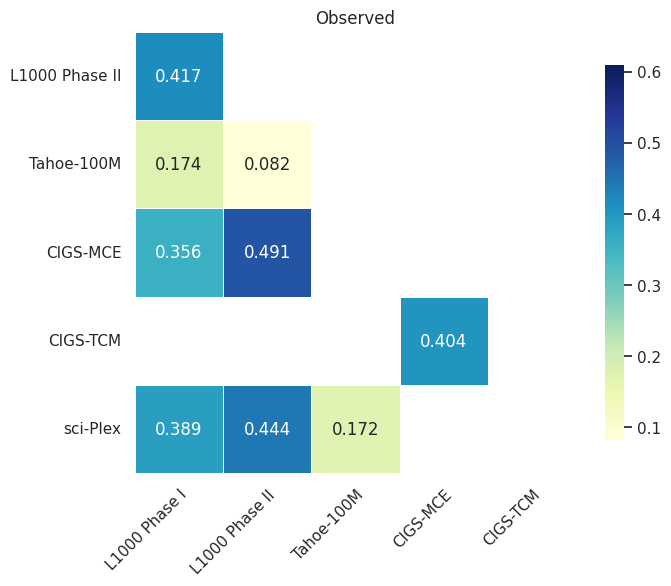

Saved heatmap to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_observed_deg_t_spearman_sym_p05_heatmap.pdf
Saved heatmap matrix CSV to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_observed_deg_t_spearman_sym_p05_heatmap.csv
Saved heatmap display CSV to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_observed_deg_t_spearman_sym_p05_heatmap_display.csv


In [17]:
plot_pair_metric_heatmap(
    pair_metric_summary,
    value_col="mean_observed_deg_t_spearman_sym_p05",
    title="Observed",
    cmap="YlGnBu",
    output_path=DEG_HEATMAP_OUTPUT_PATHS["mean_observed_deg_t_spearman_sym_p05"],
    dataset_order=heatmap_dataset_order,
    vmin=t_vmin,
    vmax=t_vmax,
    cbar_label="Mean observed DEG moderated-t Spearman",
)


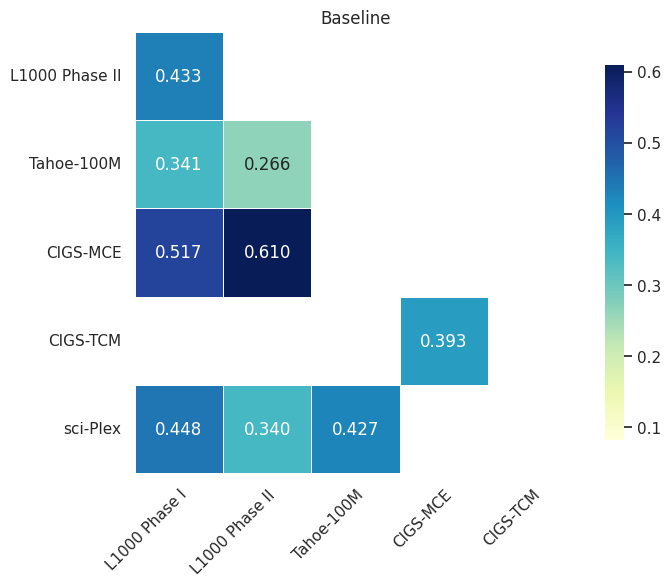

Saved heatmap to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_baseline_pair_deg_t_spearman_p05_heatmap.pdf
Saved heatmap matrix CSV to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_baseline_pair_deg_t_spearman_p05_heatmap.csv
Saved heatmap display CSV to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_baseline_pair_deg_t_spearman_p05_heatmap_display.csv


In [18]:
plot_pair_metric_heatmap(
    pair_metric_summary,
    value_col="mean_baseline_pair_deg_t_spearman_p05",
    title="Baseline",
    cmap="YlGnBu",
    output_path=DEG_HEATMAP_OUTPUT_PATHS["mean_baseline_pair_deg_t_spearman_p05"],
    dataset_order=heatmap_dataset_order,
    vmin=t_vmin,
    vmax=t_vmax,
    cbar_label="Mean baseline pair DEG moderated-t Spearman",
)


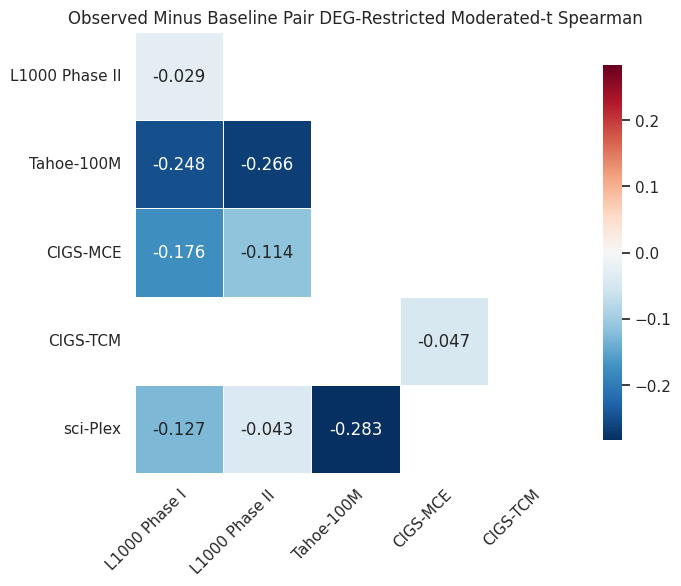

Saved heatmap to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_delta_vs_baseline_pair_deg_t_spearman_p05_heatmap.pdf
Saved heatmap matrix CSV to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_delta_vs_baseline_pair_deg_t_spearman_p05_heatmap.csv
Saved heatmap display CSV to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_delta_vs_baseline_pair_deg_t_spearman_p05_heatmap_display.csv


In [19]:
plot_pair_metric_heatmap(
    pair_metric_summary,
    value_col="mean_delta_vs_baseline_pair_deg_t_spearman_p05",
    title="Observed Minus Baseline Pair DEG-Restricted Moderated-t Spearman",
    cmap="RdBu_r",
    output_path=DEG_HEATMAP_OUTPUT_PATHS["mean_delta_vs_baseline_pair_deg_t_spearman_p05"],
    dataset_order=heatmap_dataset_order,
    vmin=None if t_delta_abs_max is None else -t_delta_abs_max,
    vmax=None if t_delta_abs_max is None else t_delta_abs_max,
    center=0.0,
    cbar_label="Mean delta DEG moderated-t Spearman",
)


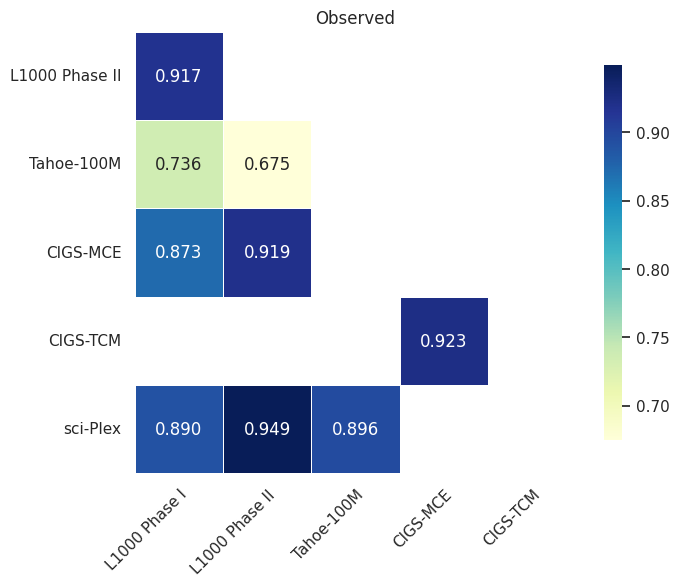

Saved heatmap to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_observed_direction_agreement_p05_heatmap.pdf
Saved heatmap matrix CSV to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_observed_direction_agreement_p05_heatmap.csv
Saved heatmap display CSV to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_observed_direction_agreement_p05_heatmap_display.csv


In [20]:
plot_pair_metric_heatmap(
    pair_metric_summary,
    value_col="mean_observed_direction_agreement_p05",
    title="Observed",
    cmap="YlGnBu",
    output_path=DEG_HEATMAP_OUTPUT_PATHS["mean_observed_direction_agreement_p05"],
    dataset_order=heatmap_dataset_order,
    vmin=dir_vmin,
    vmax=dir_vmax,
    cbar_label="Mean observed direction agreement",
)


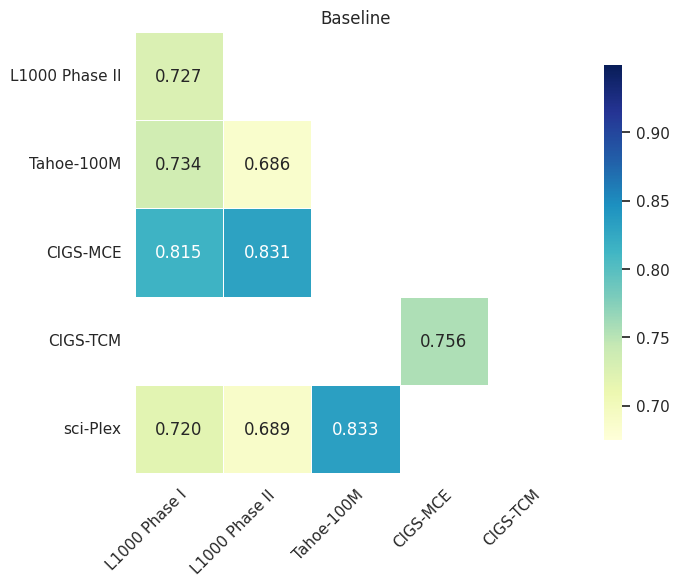

Saved heatmap to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_baseline_pair_direction_agreement_p05_heatmap.pdf
Saved heatmap matrix CSV to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_baseline_pair_direction_agreement_p05_heatmap.csv
Saved heatmap display CSV to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_baseline_pair_direction_agreement_p05_heatmap_display.csv


In [21]:
plot_pair_metric_heatmap(
    pair_metric_summary,
    value_col="mean_baseline_pair_direction_agreement_p05",
    title="Baseline",
    cmap="YlGnBu",
    output_path=DEG_HEATMAP_OUTPUT_PATHS["mean_baseline_pair_direction_agreement_p05"],
    dataset_order=heatmap_dataset_order,
    vmin=dir_vmin,
    vmax=dir_vmax,
    cbar_label="Mean baseline pair direction agreement",
)


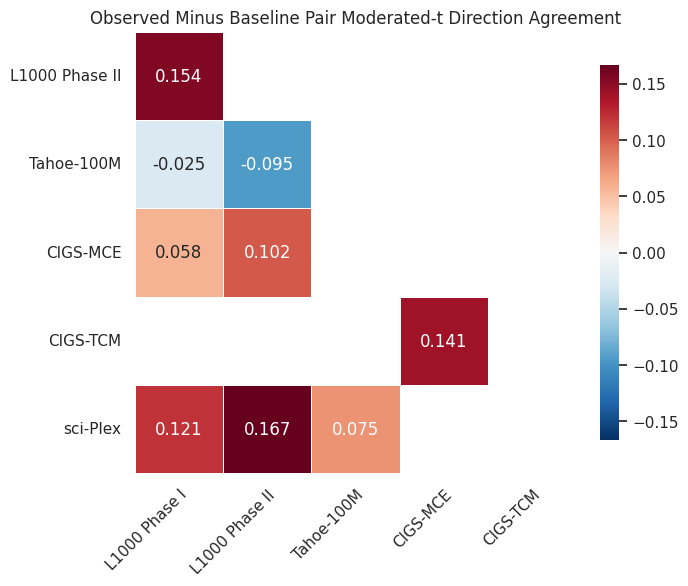

Saved heatmap to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_delta_vs_baseline_pair_direction_agreement_p05_heatmap.pdf
Saved heatmap matrix CSV to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_delta_vs_baseline_pair_direction_agreement_p05_heatmap.csv
Saved heatmap display CSV to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis/results/overlap_group_rep_deg_metrics_t_stats/dataset_pair_mean_delta_vs_baseline_pair_direction_agreement_p05_heatmap_display.csv


In [22]:
plot_pair_metric_heatmap(
    pair_metric_summary,
    value_col="mean_delta_vs_baseline_pair_direction_agreement_p05",
    title="Observed Minus Baseline Pair Moderated-t Direction Agreement",
    cmap="RdBu_r",
    output_path=DEG_HEATMAP_OUTPUT_PATHS["mean_delta_vs_baseline_pair_direction_agreement_p05"],
    dataset_order=heatmap_dataset_order,
    vmin=None if dir_delta_abs_max is None else -dir_delta_abs_max,
    vmax=None if dir_delta_abs_max is None else dir_delta_abs_max,
    center=0.0,
    cbar_label="Mean delta direction agreement",
)
